<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-069-circuits-gradients.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 069. Parametrised circuits and their gradients

The ground state of a chain of $N$ interacting spins is described by $2^N$ complex amplitudes, and already for a few dozen spins no classical computer can store them. Decades of work produced classical approximations that avoid storing all amplitudes, from mean-field theory to tensor networks and Monte Carlo sampling, each with its own limitation. A register of $N$ controlled qubits holds such a state natively. We let a circuit with adjustable gate angles prepare a trial state on the register, estimate its energy from measured bit strings and change the angles until the energy is as low as the circuit allows. By the variational principle the lowest energy reached is an upper bound on the ground-state energy, and it approaches the ground-state energy when the circuit can prepare a state close to the ground state.

The running model is the transverse-field Ising chain of six qubits. Its exact ground-state energy follows from a $64\times64$ sparse matrix, so every number of the variational calculation can be compared with the exact answer. We are given the Hamiltonian, a register initialised in $|0\dots0\rangle$, single-qubit rotations, controlled-$\hat Z$ gates between neighbours, and measurements of all qubits in the $z$ basis or in the $x$ basis. We compute the energy of the trial state exactly and from simulated bit strings, the derivative of the energy with respect to every angle, and the number of circuit runs that one gradient costs on a quantum device.

Section 2 counts the memory that a many-body state needs, and Section 3 states the variational principle and the model. Section 4 applies mean-field theory to the spin chain and compares its energy and correlations with the exact results. Section 5 introduces the parametrised circuit as a fully quantum ansatz. Sections 6 to 9 build a state-vector simulator, the hardware-efficient circuit and the energy estimated from bit strings. Sections 10 to 12 show that the energy depends on each angle as a cosine, derive the parameter-shift rule from this cosine and count the cost of a gradient on a device. Section 13 closes the loop with a short training run.

The classroom route consists of Sections 1 to 13 and stops at the end of Section 13, when the trained circuit has come close to the exact ground state of the six-spin chain. Section 14, for work at home, estimates the gradient itself from bit strings. An appendix, also for work at home, applies mean-field theory to bosons in a trap, where it gives the Gross–Pitaevskii equation, and describes tensor networks and Monte Carlo methods. The cell that saves the numbers of the notebook follows the appendix and needs every code cell above it.

Quantities called exact come from the state vector, which a simulation knows and a device does not. Quantities called estimated come from simulated measurement records with fixed random seeds, in the form a device would return them.

## 1. Double-precision arithmetic

We work in double precision, `float64` and `complex128`, so that identities hold to about $10^{-12}$. JAX applies the gates, differentiates the energy and draws random numbers on the CPU, SciPy diagonalises the sparse Hamiltonian, and Matplotlib draws the figures. The cells run in order.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"   # small calculations; the CPU avoids GPU memory allocation
import json, time
from functools import partial
from pathlib import Path
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import eigsh
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)
CDTYPE = jnp.complex128
TOL = 1e-12
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 10, "figure.figsize": (4.8, 3.2), "savefig.bbox": "tight"})
# course palette: HEA blue, HVA orange, exact black, mean field grey (dashed), random baseline light grey
COL = dict(hea="#005CA7", hva="#D35A05", spa="#1B7F36", exact="black", mf="#5A6270", rand="#9AA0A6",
           data="#3E8FD0", navy="#002B5C")
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})   # TrueType fonts: the PDFs embed cleanly in LaTeX
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)
started = time.perf_counter()
NUMBERS = {}
def sci(x, digits=1):
    # LaTeX form of a number in scientific notation for the macro file, e.g. 1.1\times10^{5} (used in math mode)
    m, e = f"{x:.{digits}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
key = jax.random.PRNGKey(69)
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. The cost of storing a many-body state

A state of $N$ spins-1/2 is a vector of $2^N$ complex amplitudes, one for every bit string. In double precision each amplitude takes 16 bytes, so the state alone needs $16\cdot2^N$ bytes, and the Hamiltonian as a dense matrix needs $16\cdot4^N$ bytes. Ten spins fit into 16 kilobytes, thirty spins need 17 gigabytes, the memory of a large workstation, and fifty spins need about 18 petabytes. Finding the ground state, or following the evolution in time, requires repeated products of the Hamiltonian with such vectors, so the cost of an exact calculation grows by a factor of two with every added spin. Exact diagonalisation is therefore limited to a few dozen spins, and larger systems need approximations that store far fewer numbers. The figure compares the memory of the state vector with that of a laptop, a compute node and an exascale supercomputer, which hold the states of at most 29, 35 and 52 spins.

N = 10: 2^N = 1.024e+03 amplitudes, state vector 1.64e+04 bytes, dense Hamiltonian 1.68e+07 bytes
N = 30: 2^N = 1.074e+09 amplitudes, state vector 1.72e+10 bytes, dense Hamiltonian 1.84e+19 bytes
N = 50: 2^N = 1.126e+15 amplitudes, state vector 1.80e+16 bytes, dense Hamiltonian 2.03e+31 bytes
largest N that fits: {'laptop, 16 GB': 29, 'compute node, 1 TB': 35, 'exascale machine, $10^{17}$ B': 52}


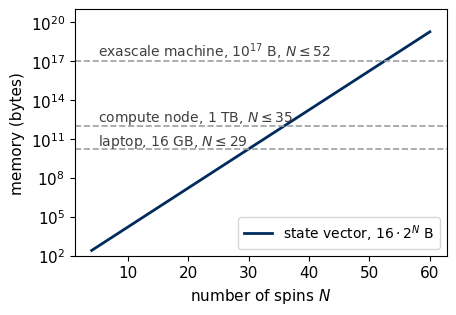

In [2]:
for N_mem in (10, 30, 50):
    vec = 16 * 2.0 ** N_mem
    print(f"N = {N_mem:2d}: 2^N = {2 ** N_mem:.3e} amplitudes, state vector {vec:.2e} bytes, dense Hamiltonian {16 * 4.0 ** N_mem:.2e} bytes")
NUMBERS.update(MemTen=f"{16 * 2 ** 10 / 1024:.0f}", MemThirty=f"{16 * 2.0 ** 30 / 1e9:.0f}", MemFifty=f"{16 * 2.0 ** 50 / 1e15:.0f}")

# the memory wall: bytes of a state vector against N, compared with the memory of real computers
N_axis = np.arange(4, 61)
LIMITS = {"laptop, 16 GB": 16e9, "compute node, 1 TB": 1e12, "exascale machine, $10^{17}$ B": 1e17}
fig, ax = plt.subplots()
ax.semilogy(N_axis, 16 * 2.0 ** N_axis, "-", color=COL["navy"], lw=2, label=r"state vector, $16\cdot2^N$ B")
for (lab, mem), y_off in zip(LIMITS.items(), (1.0, 1.0, 1.0)):
    N_max = int(np.floor(np.log2(mem / 16)))
    ax.axhline(mem, color=COL["rand"], lw=1.2, ls="--")
    ax.text(5, mem * 2.2, f"{lab}, $N\\leq{N_max}$", fontsize=10, color="0.25")
    NUMBERS[{"laptop, 16 GB": "MemMaxLaptop", "compute node, 1 TB": "MemMaxNode"}.get(lab, "MemMaxExa")] = f"{N_max}"
ax.set_xlabel(r"number of spins $N$"); ax.set_ylabel("memory (bytes)")
ax.set_ylim(1e2, 1e21); ax.legend(loc="lower right")
save(fig, "fig_lab069_memory_wall"); plt.show()
print("largest N that fits:", {k: int(np.floor(np.log2(v / 16))) for k, v in LIMITS.items()})

## 3. The variational principle and the Ising chain

The Hamiltonian $\hat{\mathcal H}$ of a system is the Hermitian matrix of its energy. Its eigenvalues $E_0\le E_1\le E_2\le\dots$ are the energy levels, with eigenvectors $|E_m\rangle$, and the eigenvector $|E_0\rangle$ of the lowest level is the ground state. The eigenvectors form an orthonormal basis, so any normalised state can be expanded as $|\psi\rangle=\sum_m c_m|E_m\rangle$ with $\sum_m|c_m|^2=1$. Its mean energy is then
$$\langle\psi|\hat{\mathcal H}|\psi\rangle=\sum_m|c_m|^2E_m\;\ge\;E_0\sum_m|c_m|^2=E_0 , \tag{1}$$
because every $E_m$ in the sum is at least $E_0$. Equality holds only when all the weight sits on ground states. Every trial state therefore gives an upper bound on the ground-state energy. Minimising the energy over a family of trial states $|\psi(\boldsymbol\theta)\rangle$, called the ansatz, gives the best bound that the family allows, and this procedure is the Rayleigh–Ritz variational method. The sketch shows the energy levels of $\hat{\mathcal H}$ with the weights of a trial state, whose mean energy therefore lies above $E_0$.

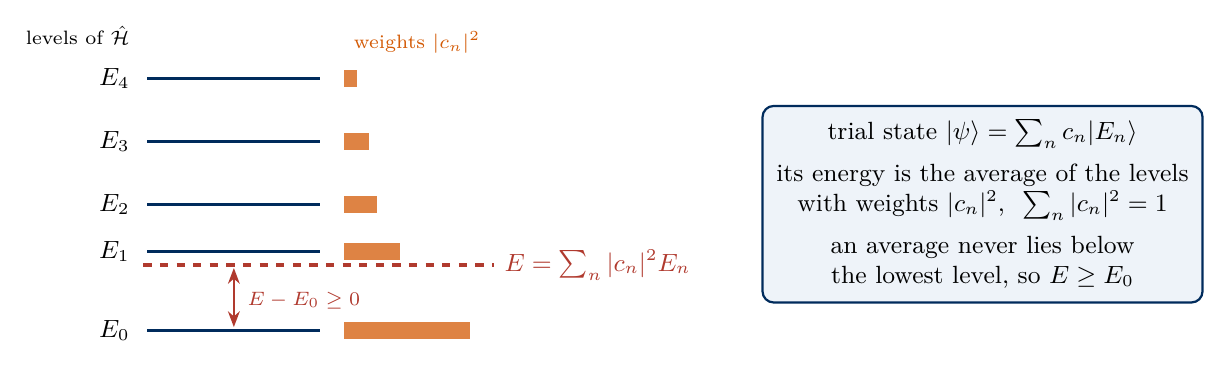

*Energy levels $E_n$ of $\hat{\mathcal H}$, the weights $|c_n|^2$ of a trial state and its mean energy $E=\sum_n|c_n|^2E_n\ge E_0$.*

The energy error also controls how close the trial state is to the ground state. Writing the fidelity $F=|\langle E_0|\psi\rangle|^2=|c_0|^2$ and the gap $\Delta E=E_1-E_0$, and subtracting $E_0$ from equation (1), gives
$$E-E_0=\sum_{m\ge1}|c_m|^2(E_m-E_0)\;\ge\;\Delta E\,(1-F) . \tag{2}$$
A small energy error guarantees a fidelity close to one only when it is small compared with the gap. The sketch shows the region that equation (2) allows in the plane of infidelity $1-F$ and energy error $E-E_0$.

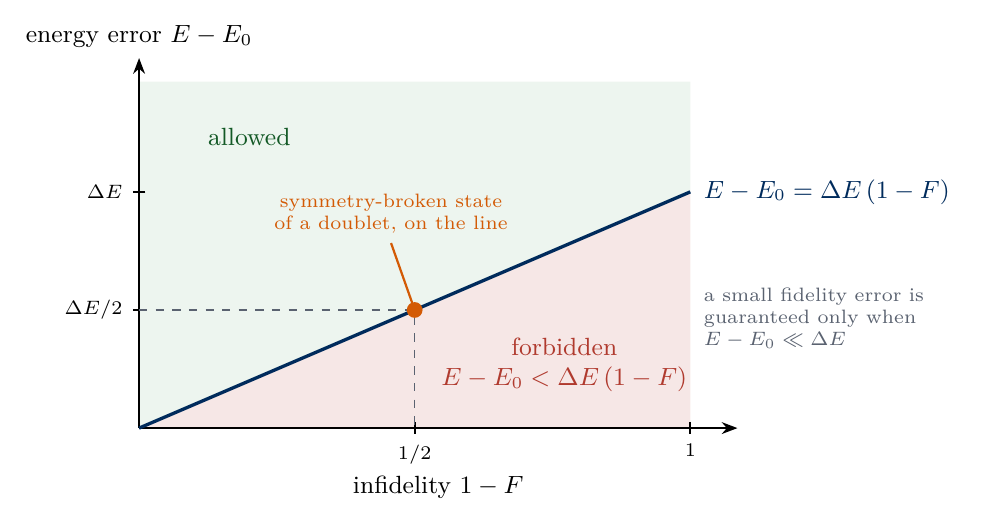

*Energy error against infidelity. States below the line $E-E_0=\Delta E\,(1-F)$ do not exist, so a small fidelity error is guaranteed only when $E-E_0\ll\Delta E$.*

The running model is the transverse-field Ising model (TFIM) on an open chain of $N$ spins,
$$\hat{\mathcal H}=-J\sum_{i=0}^{N-2}\hat Z_i\hat Z_{i+1}-h\sum_{i=0}^{N-1}\hat X_i , \tag{3}$$
where $\hat Z_i$ and $\hat X_i$ act on qubit $i$. The coupling $J>0$ lowers the energy when neighbouring spins point the same way along $z$, and the transverse field $h$ lowers it when each spin points along $+x$. The two terms do not commute, so the ground state is a superposition of many bit strings. For $h<J$ the chain is in the ordered phase and for $h>J$ in the paramagnetic phase, and we take the critical point $J=h=1$ between them, with $N=6$. Two product states give upper bounds directly. In $|0\dots0\rangle$ every $\hat Z_i\hat Z_{i+1}$ equals $+1$ and every $\langle\hat X_i\rangle$ vanishes, so the energy is $-J(N-1)$. In $|{+}\dots{+}\rangle$, with $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$, every $\langle\hat X_i\rangle=1$ and every $\langle\hat Z_i\hat Z_{i+1}\rangle=0$, so the energy is $-hN$.

The code builds $\hat{\mathcal H}$ from Kronecker products of $2\times2$ matrices, stored as a sparse matrix, and finds the two lowest eigenvalues with `eigsh`, an iterative eigensolver for the extreme eigenvalues of sparse Hermitian matrices based on the Lanczos method [1].

In [3]:
N, J, h = 6, 1.0, 1.0
SPARSE = {"I": sp.identity(2, format="csr", dtype=complex),
          "X": sp.csr_matrix(np.array([[0, 1], [1, 0]], dtype=complex)),
          "Z": sp.csr_matrix(np.array([[1, 0], [0, -1]], dtype=complex))}

def pauli_string(N, factors):
    # Kronecker product over qubits 0..N-1 (qubit 0 leftmost); factors = {qubit: "X" or "Z"}
    out = sp.identity(1, format="csr", dtype=complex)
    for q in range(N):
        out = sp.kron(out, SPARSE[factors.get(q, "I")], format="csr")
    return out

def tfim_sparse(N, J, h):
    H = sp.csr_matrix((2 ** N, 2 ** N), dtype=complex)
    for i in range(N - 1):
        H = H - J * pauli_string(N, {i: "Z", i + 1: "Z"})
    for i in range(N):
        H = H - h * pauli_string(N, {i: "X"})
    return H

H_sp = tfim_sparse(N, J, h)
evals, evecs = eigsh(H_sp, k=2, which="SA")
order = np.argsort(evals); evals, evecs = evals[order], evecs[:, order]
E0, E1 = float(evals[0]), float(evals[1])
psi_ground = evecs[:, 0]
assert np.allclose(np.linalg.eigvalsh(H_sp.toarray())[:2], [E0, E1], atol=1e-10)

def expect_sparse(psi_vec):
    return float(np.real(np.vdot(psi_vec, H_sp @ psi_vec)))

zeros_state = np.zeros(2 ** N, dtype=complex); zeros_state[0] = 1.0
plus_state = np.ones(2 ** N, dtype=complex) / 2 ** (N / 2)
E_zeros, E_plus = expect_sparse(zeros_state), expect_sparse(plus_state)
assert abs(E_zeros - (-J * (N - 1))) < TOL and abs(E_plus - (-h * N)) < TOL
assert E_zeros >= E0 and E_plus >= E0
print(f"N = {N}, J = {J}, h = {h}: {H_sp.nnz} nonzero entries of a {2**N} x {2**N} matrix")
print(f"exact E_0 = {E0:.6f}, E_1 = {E1:.6f}, gap = {E1 - E0:.4f}")
print(f"upper bounds: E(|0...0>) = {E_zeros:.1f}, E(|+...+>) = {E_plus:.1f}")
NUMBERS.update(N=f"{N}", EZero=f"{E0:.4f}", EOne=f"{E1:.4f}", Gap=f"{E1 - E0:.3f}",
               EZeros=f"{E_zeros:.0f}", EPlus=f"{E_plus:.0f}")

N = 6, J = 1.0, h = 1.0: 448 nonzero entries of a 64 x 64 matrix
exact E_0 = -7.296230, E_1 = -6.814083, gap = 0.4821
upper bounds: E(|0...0>) = -5.0, E(|+...+>) = -6.0


Both product states lie above the exact ground-state energy, as equation (1) requires, and $|{+}\dots{+}\rangle$ is the better of the two at $h=J$. Both belong to the family of product states of the next section, which contains better bounds.

## 4. Mean-field theory of the Ising chain

Mean-field theory is the simplest classical approximation to a many-body ground state. For any many-body system it chooses a product ansatz without entanglement, in which every particle occupies the same single-particle state, computes the energy as a functional of that state and minimises it. The interaction then enters as an average field produced by all other particles, and the minimum satisfies a nonlinear self-consistent equation. The approximation is accurate when the true ground state is close to a product state, as for dilute and weakly interacting Bose gases, and it fails where correlations between the particles matter. The appendix applies the same idea to bosons in a trap, where it gives the Gross–Pitaevskii equation.

For the spin chain the same logic replaces the ground state by a product state in which every spin is in the same single-qubit state,
$$|\psi_{\mathrm{MF}}(\theta)\rangle=|\phi(\theta)\rangle^{\otimes N},\qquad |\phi(\theta)\rangle=\cos\frac\theta2\,|0\rangle+\sin\frac\theta2\,|1\rangle=\hat R_y(\theta)|0\rangle . \tag{10}$$
The angle $\theta$ is the polar angle of the Bloch vector in the $xz$ plane, so $\langle\hat Z_i\rangle=\cos\theta$ and $\langle\hat X_i\rangle=\sin\theta$ for every spin. A $\hat Y$ component cannot lower the energy of $\hat{\mathcal H}$ and is left out. The state is stored as a single angle in place of $2^N$ amplitudes. In a product state the expectation value of $\hat Z_i\hat Z_{i+1}$ factorises into $\langle\hat Z_i\rangle\langle\hat Z_{i+1}\rangle=\cos^2\theta$, and the energy (3) of the open chain becomes
$$E_{\mathrm{MF}}(\theta)=-J(N-1)\cos^2\theta-hN\sin\theta . \tag{11}$$
It is an upper bound on $E_0$ by equation (1). The best angle makes the derivative vanish,
$$\frac{dE_{\mathrm{MF}}}{d\theta}=\cos\theta\,\big[2J(N-1)\sin\theta-hN\big]=0 . \tag{12}$$
This stationarity condition is the self-consistency equation of mean-field theory. Each spin feels the transverse field $h$ and a longitudinal field $2J(N-1)\langle\hat Z\rangle/N$ from its neighbours, where $2(N-1)/N$ is the average number of neighbours on the open chain. The Bloch vector of the spin points along the total field, $\tan\theta=hN/[2J(N-1)\cos\theta]$, which is equation (12) for $\cos\theta\neq0$. The minimum of equation (11) is
$$\sin\theta^*=\frac{h}{h_c^{\mathrm{MF}}},\quad E_{\mathrm{MF}}=-J(N-1)-\frac{h^2N^2}{4J(N-1)}\quad\text{for } h<h_c^{\mathrm{MF}}=\frac{2J(N-1)}N,\qquad \theta^*=\frac\pi2,\quad E_{\mathrm{MF}}=-hN\quad\text{for } h\ge h_c^{\mathrm{MF}} . \tag{13}$$
Below $h_c^{\mathrm{MF}}$ the spins tilt away from $z$ and keep a magnetisation $\langle\hat Z\rangle=\pm\cos\theta^*$, with two degenerate solutions related by the spin flip $\hat Z\to-\hat Z$. Above it they all point along $x$. In a long chain the mean-field transition lies at $h_c^{\mathrm{MF}}=2J$, twice the exact critical field $h_c=J$. The product states $|0\dots0\rangle$ and $|{+}\dots{+}\rangle$ of Section 3 are the members $\theta=0$ and $\theta=\pi/2$ of this family.

The code evaluates equation (13) on a grid of fields and checks it against a numerical minimisation of equation (11). It then compares the energy per spin, $\langle\hat X_i\rangle$ and the nearest-neighbour correlator $\langle\hat Z_i\hat Z_{i+1}\rangle$, averaged over the chain, with the exact ground state of $N=6$ spins. Each mean-field curve is compared with the exact result for the same system. For the infinite chain the mean-field energy per spin, $-J-h^2/4J$ for $h<2J$ and $-h$ above, is compared with the exact energy per spin, which follows from a mapping of the chain onto free fermions [4],
$$e_\infty(h)=-\frac1\pi\int_0^\pi dk\,\sqrt{J^2+h^2-2Jh\cos k} . \tag{14}$$
The code checks equation (14) at $h=0$, where it gives $-J$, at large $h$, where it approaches $-h$, and against the energy per bulk spin $[E_0(12)-E_0(10)]/2$ of open chains from exact diagonalisation.

N = 6, h = 1.0: mean field sin(theta*) = 0.600, E_MF = -6.8000; exact E_0 = -7.2962
relative energy error of mean field at h = J: 0.068
<X>:  mean field 0.600, exact 0.771;   <Z Z>: mean field 0.640, exact 0.534
h = 0.5: energy per bulk spin [E_0(12) - E_0(10)]/2 = -1.06327, equation (14) = -1.06354
h = 1.0: energy per bulk spin [E_0(12) - E_0(10)]/2 = -1.27224, equation (14) = -1.27324
h = 1.5: energy per bulk spin [E_0(12) - E_0(10)]/2 = -1.67193, equation (14) = -1.67193
mean-field transition h_c^MF = 2J(N-1)/N = 1.667 for N = 6, 2J for the infinite chain; exact bulk h_c = J


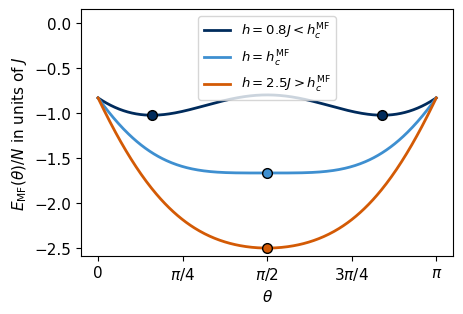

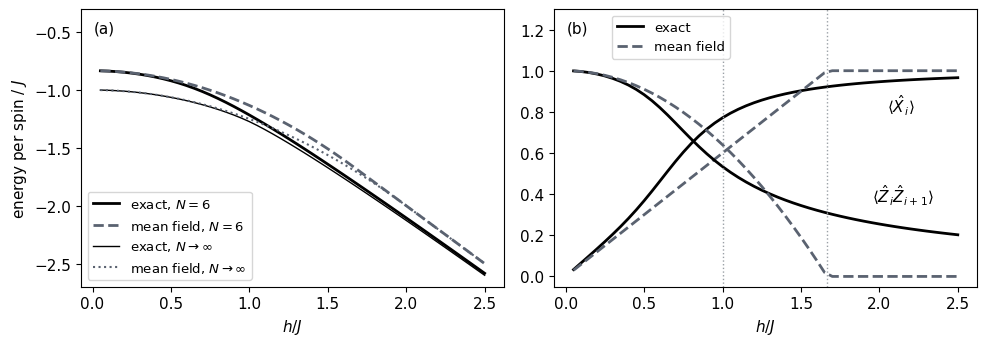

In [5]:
def mean_field(N, J, h):
    # equation (13): optimal angle and energy of the uniform product state
    hc = 2 * J * (N - 1) / N
    theta = np.arcsin(np.minimum(h / hc, 1.0))
    return theta, -J * (N - 1) * np.cos(theta) ** 2 - h * N * np.sin(theta)

def sum_ops(N):
    ZZ = sum(pauli_string(N, {i: "Z", i + 1: "Z"}) for i in range(N - 1))
    XX = sum(pauli_string(N, {i: "X"}) for i in range(N))
    return ZZ, XX

h_grid = np.linspace(0.05, 2.5, 50)
exact = {}
for N_ex in (6,):
    ZZ_ex, X_ex = sum_ops(N_ex)
    rows = []
    for hv in h_grid:
        w, v = eigsh(-J * ZZ_ex - hv * X_ex, k=1, which="SA")
        g = v[:, 0]
        rows.append((w[0] / N_ex, np.vdot(g, X_ex @ g).real / N_ex, np.vdot(g, ZZ_ex @ g).real / (N_ex - 1)))
    exact[N_ex] = np.array(rows)
theta_mf, E_mf = mean_field(N, J, h_grid)

def e_infinite(hv, n_k=4001):
    # equation (14), trapezoidal rule in k
    k = np.linspace(0, np.pi, n_k)
    return -np.trapezoid(np.sqrt(J ** 2 + hv ** 2 - 2 * J * hv * np.cos(k)), k) / np.pi

e_inf = np.array([e_infinite(hv) for hv in h_grid])
e_mf_inf = np.where(h_grid < 2 * J, -J - h_grid ** 2 / (4 * J), -h_grid)
assert abs(e_infinite(0.0) + J) < 1e-12 and abs(e_infinite(100.0) + 100.0) < 0.01
bulk_check = []
for hv in (0.5, 1.0, 1.5):
    E10, E12 = (eigsh(-J * sum_ops(Nb)[0] - hv * sum_ops(Nb)[1], k=1, which="SA")[0][0] for Nb in (10, 12))
    bulk_check.append((hv, (E12 - E10) / 2, e_infinite(hv)))
    assert abs((E12 - E10) / 2 - e_infinite(hv)) < 1e-2
assert np.all(e_mf_inf >= e_inf - 1e-12)          # mean field above the exact energy for the infinite chain
# checks: grid minimisation of equation (11), the variational bound, and the two product states of Section 3
th_fine = np.linspace(-np.pi, np.pi, 20001)
E_grid = -J * (N - 1) * np.cos(th_fine)[None, :] ** 2 - h_grid[:, None] * N * np.sin(th_fine)[None, :]
assert np.allclose(E_grid.min(axis=1), E_mf, atol=1e-6)
assert np.all(E_mf / N >= exact[6][:, 0] - 1e-12)  # and for N = 6
assert mean_field(N, J, h)[1] <= min(E_zeros, E_plus)
theta_star, E_mf_h1 = mean_field(N, J, h)
x_mf, zz_mf = np.sin(theta_mf), np.cos(theta_mf) ** 2
i1 = int(np.argmin(np.abs(h_grid - 1.0)))
psi_g1 = psi_ground
x_ex1 = np.vdot(psi_g1, sum_ops(N)[1] @ psi_g1).real / N
zz_ex1 = np.vdot(psi_g1, sum_ops(N)[0] @ psi_g1).real / (N - 1)
hc_mf = 2 * J * (N - 1) / N
print(f"N = {N}, h = {h}: mean field sin(theta*) = {np.sin(theta_star):.3f}, E_MF = {E_mf_h1:.4f}; exact E_0 = {E0:.4f}")
print(f"relative energy error of mean field at h = J: {(E_mf_h1 - E0) / abs(E0):.3f}")
print(f"<X>:  mean field {np.sin(theta_star):.3f}, exact {x_ex1:.3f};   <Z Z>: mean field {np.cos(theta_star)**2:.3f}, exact {zz_ex1:.3f}")
for hv, eb, ei in bulk_check:
    print(f"h = {hv}: energy per bulk spin [E_0(12) - E_0(10)]/2 = {eb:.5f}, equation (14) = {ei:.5f}")
print(f"mean-field transition h_c^MF = 2J(N-1)/N = {hc_mf:.3f} for N = {N}, 2J for the infinite chain; exact bulk h_c = J")

# mean-field energy per spin against theta, equation (11), below, at and above h_c^MF
th_plot = np.linspace(0, np.pi, 401)
fig, ax = plt.subplots()
for hv, col, lab in ((0.8, COL["navy"], r"$h=0.8J<h_c^{\mathrm{MF}}$"), (hc_mf, COL["data"], r"$h=h_c^{\mathrm{MF}}$"),
                     (2.5, COL["hva"], r"$h=2.5J>h_c^{\mathrm{MF}}$")):
    e_th = (-J * (N - 1) * np.cos(th_plot) ** 2 - hv * N * np.sin(th_plot)) / N
    ax.plot(th_plot, e_th, color=col, lw=2, label=lab)
    t_opt = mean_field(N, J, hv)[0]
    for t_min in sorted({round(float(t_opt), 12), round(float(np.pi - t_opt), 12)}):
        ax.plot(t_min, (-J * (N - 1) * np.cos(t_min) ** 2 - hv * N * np.sin(t_min)) / N, "o", color=col, ms=7, mec="black")
ax.set_xticks([0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi])
ax.set_xticklabels(["0", r"$\pi/4$", r"$\pi/2$", r"$3\pi/4$", r"$\pi$"])
ax.set_xlabel(r"$\theta$"); ax.set_ylabel(r"$E_{\mathrm{MF}}(\theta)/N$ in units of $J$")
ax.set_ylim(top=0.15); ax.legend(loc="upper center", fontsize=9.5, ncol=1)
save(fig, "fig_lab069_mf_energy_theta"); plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
ax1.plot(h_grid, exact[6][:, 0], "-", color=COL["exact"], lw=2, label=r"exact, $N=6$")
ax1.plot(h_grid, E_mf / N, "--", color=COL["mf"], lw=2, label=r"mean field, $N=6$")
ax1.plot(h_grid, e_inf, "-", color=COL["exact"], lw=1, label=r"exact, $N\to\infty$")
ax1.plot(h_grid, e_mf_inf, ":", color=COL["mf"], lw=1.5, label=r"mean field, $N\to\infty$")
ax1.set_xlabel(r"$h/J$"); ax1.set_ylabel(r"energy per spin / $J$"); ax1.set_ylim(-2.7, -0.3)
ax1.legend(loc="lower left", fontsize=9.5)
ax2.plot(h_grid, exact[6][:, 1], "-", color=COL["exact"], lw=2, label="exact")
ax2.plot(h_grid, x_mf, "--", color=COL["mf"], lw=2, label="mean field")
ax2.plot(h_grid, exact[6][:, 2], "-", color=COL["exact"], lw=2)
ax2.plot(h_grid, zz_mf, "--", color=COL["mf"], lw=2)
ax2.text(2.05, 0.80, r"$\langle\hat X_i\rangle$", fontsize=11)
ax2.text(1.95, 0.36, r"$\langle\hat Z_i\hat Z_{i+1}\rangle$", fontsize=11)
ax2.axvline(J, color=COL["rand"], lw=1, ls=":"); ax2.axvline(hc_mf, color=COL["rand"], lw=1, ls=":")
ax2.set_xlabel(r"$h/J$"); ax2.set_ylim(-0.05, 1.3); ax2.legend(loc="upper left", bbox_to_anchor=(0.12, 1.0), fontsize=9.5)
for ax, lab in ((ax1, "(a)"), (ax2, "(b)")):
    ax.text(0.03, 0.96, lab, transform=ax.transAxes, va="top", fontsize=11)
fig.tight_layout()
save(fig, "fig_lab069_mean_field"); plt.show()
NUMBERS.update(MFEnergy=f"{E_mf_h1:.3f}", MFRelErr=f"{(E_mf_h1 - E0) / abs(E0):.3f}", MFSinTheta=f"{np.sin(theta_star):.2f}",
               MFX=f"{np.sin(theta_star):.2f}", ExactX=f"{x_ex1:.3f}", MFZZ=f"{np.cos(theta_star) ** 2:.2f}", ExactZZ=f"{zz_ex1:.3f}",
               MFhc=f"{hc_mf:.3f}", EInfExactOne=f"{e_infinite(1.0):.4f}", EInfMFOne=f"{-J - 1 / (4 * J):.4f}",
               EBulkEDOne=f"{bulk_check[1][1]:.4f}")

The first figure shows the mean-field energy per spin as a function of $\theta$. Below $h_c^{\mathrm{MF}}$ it has two minima at $\theta^*$ and $\pi-\theta^*$, the two magnetised solutions with $\langle\hat Z\rangle=\pm\cos\theta^*$, which merge at $h_c^{\mathrm{MF}}$ into a single flat minimum at $\theta=\pi/2$ that stays the only minimum above it. Panel (a) of the second figure compares each mean-field energy with the exact energy of the same system, the six-spin chain with thick lines and the infinite chain with thin lines, exact results in black and mean field in grey. Every mean-field curve lies above its exact counterpart, as a variational bound must, and the difference is largest between the exact critical point $h=J$ and the mean-field transition. At $h=J$ the mean-field energy of the six-spin chain lies about $0.5J$ above $E_0$. Far from the critical point, at small and at large $h$, the exact ground state is close to a product state and mean field becomes accurate. Mean field places the transition at $h_c^{\mathrm{MF}}=2J$ in the infinite chain, twice the exact $h_c=J$, so it predicts a magnetisation $\cos\theta^*$ in the whole range $J<h<2J$, where the exact ground state has none, and it overestimates the order. In panel (b) the mean-field correlator $\langle\hat Z_i\hat Z_{i+1}\rangle=\cos^2\theta^*$ vanishes above $h_c^{\mathrm{MF}}$, the right dotted line, whereas the exact correlator decreases smoothly and stays positive, because quantum fluctuations correlate neighbouring spins without any magnetisation. A product state has no entanglement, so its half-chain entanglement entropy $S_{\mathrm{vN}}$ is zero by construction and it describes correlations only through the magnetisation. Mean field is therefore exact only where the ground state is a product state. In the language of circuits, the state (10) is a circuit with one $\hat R_y(\theta)$ on every qubit and no entangling gates.

## 5. Trial states prepared by a quantum device

Over the last two decades experiments in trapped ions, neutral atoms in optical tweezers and superconducting circuits have reached individual control of tens to hundreds of qubits. Each qubit is prepared in $|0\rangle$, rotated by laser or microwave pulses, coupled to its neighbours by a controlled interaction and measured. Such a register holds the $2^N$ amplitudes physically, which suggests a variational ansatz whose structure is set by the operations of the hardware, whose parameters are pulse areas and interaction times optimised by a classical computer, and whose trial state is never stored classically. A quantum processor can prepare the trial state itself [11], and the resulting hybrid quantum–classical scheme is the variational quantum eigensolver (VQE) [12]. The register starts in $|0\dots0\rangle$ and a circuit with $n$ adjustable angles $\boldsymbol\theta=(\theta_1,\dots,\theta_n)$ acts on it,
$$|\psi(\boldsymbol\theta)\rangle=\hat U(\boldsymbol\theta)\,|0\dots0\rangle,\qquad \hat U(\boldsymbol\theta)=\hat W_n\,e^{-i\theta_n\hat P_n/2}\cdots\hat W_2\,e^{-i\theta_2\hat P_2/2}\,\hat W_1\,e^{-i\theta_1\hat P_1/2} , \tag{15}$$
where each $\hat P_k$ is a Pauli string and each $\hat W_k$ is a fixed gate without an adjustable angle, often the identity. The rotation $e^{-i\theta_k\hat P_k/2}$ is a physical operation. A single-qubit rotation is a laser or microwave pulse of Rabi frequency $\Omega$ and duration $t$ with pulse area $\theta=\Omega t$, and a two-qubit rotation is an interaction of strength $J$ switched on for a time $t$, with $\theta=Jt$. The ansatz is therefore fully quantum, since the trial state exists only on the register, its $2^N$ amplitudes are never written down and the device returns bit strings.

The energy $E(\boldsymbol\theta)=\langle\psi(\boldsymbol\theta)|\hat{\mathcal H}|\psi(\boldsymbol\theta)\rangle$ is a function of $n$ real numbers, and by equation (1) it never falls below $E_0$. The calculation alternates between the device and a classical computer in a loop of four operations.

1. The classical computer sends the angles $\boldsymbol\theta$ to the device.
2. The device prepares $|\psi(\boldsymbol\theta)\rangle$, rotates the qubits into each measurement setting and records $M$ bit strings per setting.
3. The classical computer turns the bit strings into an estimate $\tilde E(\boldsymbol\theta)$ of the energy and, from further runs at shifted angles, an estimate of the gradient.
4. It updates the angles so that the energy decreases, and the loop returns to the first operation until the energy stops decreasing.

In this notebook a state-vector simulation plays the part of the device, so that every estimate can be compared with its exact value. The sketch shows the loop, with the hardware-efficient circuit of Section 7 as an example of $\hat U(\boldsymbol\theta)$.

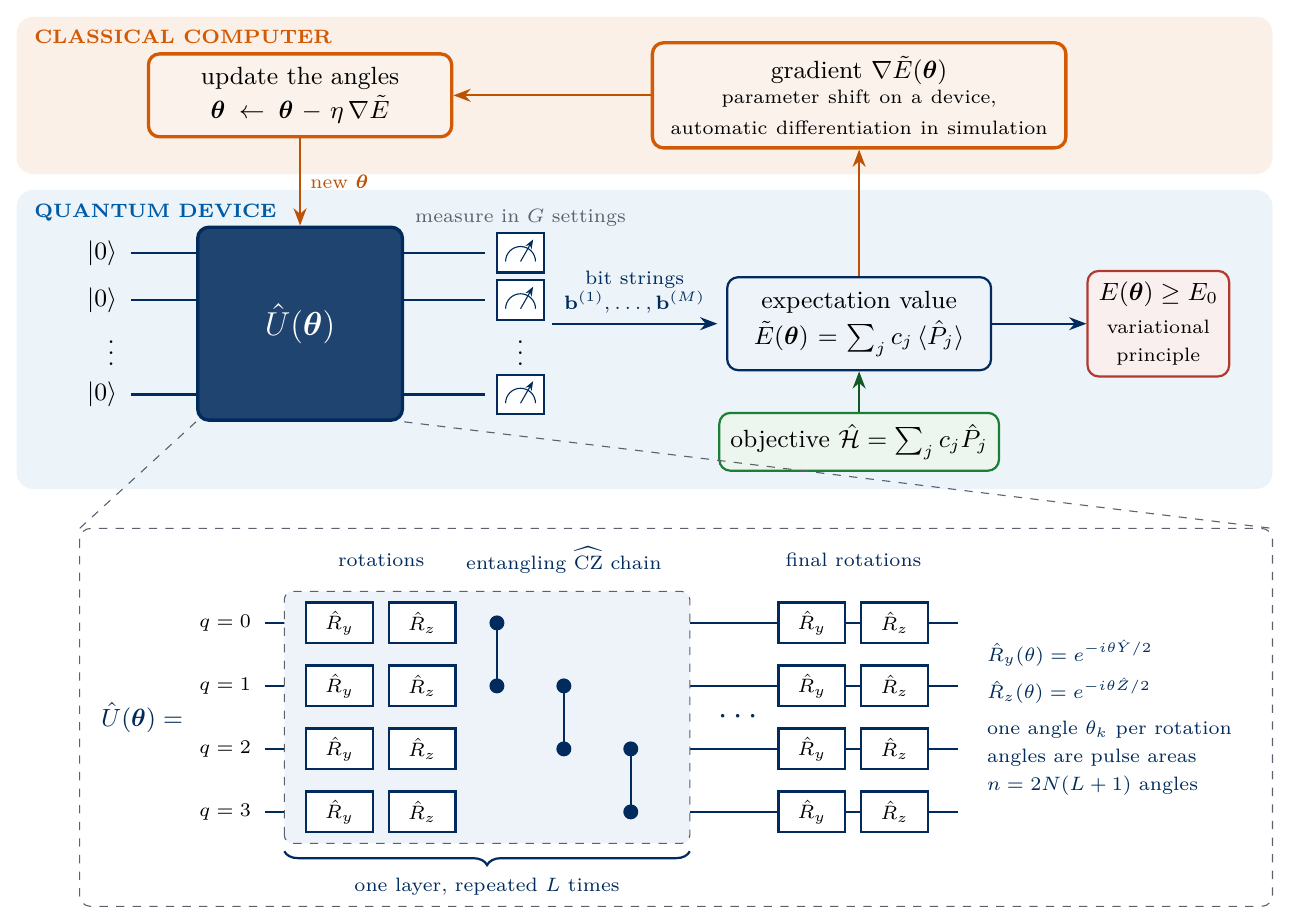

*The hybrid loop. The device prepares $\hat U(\boldsymbol\theta)|0\dots0\rangle$ and returns bit strings, and the classical computer estimates the energy and its gradient and updates the angles.*

## 6. A state-vector simulator

The state of $N$ qubits is stored as a tensor $\psi[b_0,\dots,b_{N-1}]$ with one index of dimension two per qubit, the C-order reshape of the vector of $2^N$ amplitudes, with qubit 0 as the most significant bit. A single-qubit gate with matrix $U$ acting on qubit $q$ contracts its column index with index $b_q$ of the state,
$$\psi'[b_0,\dots,b_q,\dots,b_{N-1}]=\sum_{b_q'=0,1}U_{b_qb_q'}\,\psi[b_0,\dots,b_q',\dots,b_{N-1}] . \tag{16}$$
This gives the same result as the matrix $\hat I\otimes\dots\otimes\hat U\otimes\dots\otimes\hat I$ applied to the vector, with about $2^{N+1}$ multiplications in place of $4^N$. A two-qubit gate is a tensor $U_{b_qb_r,b_q'b_r'}$ with four indices and is contracted with two indices of the state in the same way. Rotations about a Pauli matrix $\hat P$ use $\hat P^2=\hat I$,
$$\hat R_P(\theta)=e^{-i\theta\hat P/2}=\cos\frac\theta2\,\hat I-i\sin\frac\theta2\,\hat P , \tag{17}$$
and the controlled-$\hat Z$ gate $\widehat{\mathrm{CZ}}=\mathrm{diag}(1,1,1,-1)$ changes the sign of the amplitude when both qubits are in $|1\rangle$. The code checks equation (16) against the Kronecker-product matrix for $\hat R_y(0.37)$ on qubit 2 and for $\widehat{\mathrm{CZ}}$ on qubits 1 and 2 of a random four-qubit state.

In [6]:
I2 = jnp.eye(2, dtype=CDTYPE)
X = jnp.array([[0, 1], [1, 0]], dtype=CDTYPE)
Y = jnp.array([[0, -1j], [1j, 0]], dtype=CDTYPE)
Z = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)
HAD = (X + Z) / jnp.sqrt(2.0)                       # Hadamard gate
CZ = jnp.diag(jnp.array([1, 1, 1, -1], dtype=CDTYPE))

def rotation(P, theta):
    # R_P(theta) = exp(-i theta P / 2) = cos(theta/2) I - i sin(theta/2) P, equation (17)
    return jnp.cos(theta / 2) * I2 - 1j * jnp.sin(theta / 2) * P

def zero_state(N):
    return jnp.zeros((2,) * N, dtype=CDTYPE).at[(0,) * N].set(1.0)

def apply_1q(psi, U, q):
    # equation (16): contract the column index of U with index q of the state, then put the new index back at q
    return jnp.moveaxis(jnp.tensordot(U, psi, axes=([1], [q])), 0, q)

def apply_2q(psi, U, q, r):
    U4 = U.reshape(2, 2, 2, 2)                     # U[b_q b_r, b_q' b_r'] as a four-index tensor
    return jnp.moveaxis(jnp.tensordot(U4, psi, axes=([2, 3], [q, r])), [0, 1], [q, r])

def kron_all(mats):
    out = mats[0]
    for m in mats[1:]:
        out = jnp.kron(out, m)
    return out

def random_state(key, N):
    k1, k2 = jax.random.split(key)
    v = jax.random.normal(k1, (2 ** N,)) + 1j * jax.random.normal(k2, (2 ** N,))
    return (v / jnp.linalg.norm(v)).reshape((2,) * N)

psi4 = random_state(jax.random.PRNGKey(6901), 4)
U_tensor = apply_1q(psi4, rotation(Y, 0.37), 2).reshape(-1)
U_matrix = kron_all([I2, I2, rotation(Y, 0.37), I2]) @ psi4.reshape(-1)
assert jnp.allclose(U_tensor, U_matrix, atol=TOL)
CZ_tensor = apply_2q(psi4, CZ, 1, 2).reshape(-1)
CZ_matrix = jnp.kron(jnp.kron(I2, CZ), I2) @ psi4.reshape(-1)
assert jnp.allclose(CZ_tensor, CZ_matrix, atol=TOL)
assert jnp.allclose(rotation(X, jnp.pi), -1j * X, atol=TOL)
print("tensor contraction = Kronecker matrix for R_y on qubit 2 and CZ on (1, 2):",
      float(jnp.max(jnp.abs(U_tensor - U_matrix))), float(jnp.max(jnp.abs(CZ_tensor - CZ_matrix))))

tensor contraction = Kronecker matrix for R_y on qubit 2 and CZ on (1, 2): 0.0 0.0


## 7. The hardware-efficient ansatz

The hardware-efficient ansatz (HEA) is built only from gates that a device applies natively, without reference to the Hamiltonian [13]. It consists of $L$ layers. Each layer applies a rotation block, $\hat R_y$ and then $\hat R_z$ with independent angles on every qubit, followed by a chain of $\widehat{\mathrm{CZ}}$ gates on the neighbouring pairs $(0,1),(1,2),\dots,(N-2,N-1)$. A final rotation block ends the circuit, so the number of angles is
$$n=2N(L+1) . \tag{18}$$
Two angles per qubit rotate $|0\rangle$ to any point of the Bloch sphere, so the first block alone prepares any product state, including the mean-field state (10), and the $\widehat{\mathrm{CZ}}$ chains entangle neighbouring qubits. All $\widehat{\mathrm{CZ}}$ gates are diagonal and commute, and the whole chain multiplies the amplitude of the bit string $\mathbf b=b_0b_1\dots b_{N-1}$ by the sign $(-1)^{\sum_qb_qb_{q+1}}$. The code stores this sign as a tensor and checks it against the chain applied gate by gate. The sketch shows the circuit for four qubits.

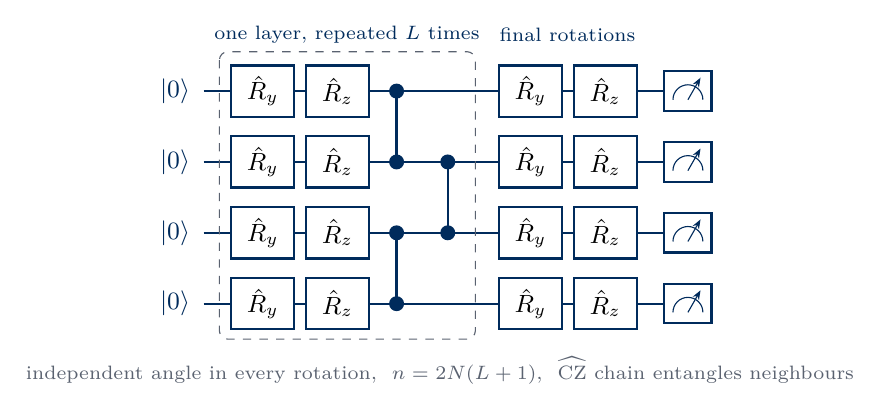

*Hardware-efficient ansatz on four qubits, with $\hat R_y\hat R_z$ rotation blocks, a $\widehat{\mathrm{CZ}}$ chain in every layer and a final rotation block.*

The angles form an array of shape $(L+1,N,2)$. The entry $[\ell,q,0]$ is the $\hat R_y$ angle of qubit $q$ in block $\ell$ and $[\ell,q,1]$ its $\hat R_z$ angle, at position $k=2(\ell N+q)+j$ of the flat vector $\boldsymbol\theta$, with $j=0$ for $\hat R_y$ and $j=1$ for $\hat R_z$. The function `jax.lax.scan` repeats one layer $L$ times inside a single compiled loop. We use $L=4$, which gives $n=60$ angles for $N=6$.

In [7]:
L = 4
def n_params(N, L):
    return 2 * N * (L + 1)                             # equation (18)

def cz_chain_sign(N):
    b = np.indices((2,) * N)                           # b[q] = bit of qubit q on every basis state
    return jnp.asarray((-1.0) ** sum(b[q] * b[q + 1] for q in range(N - 1)))

def rotation_block(psi, angles):
    # angles[q] = (R_y angle, R_z angle) of qubit q; R_y acts first
    for q in range(psi.ndim):
        psi = apply_1q(psi, rotation(Z, angles[q, 1]) @ rotation(Y, angles[q, 0]), q)
    return psi

@partial(jax.jit, static_argnums=(1, 2))      # compiled once for each (N, L)
def hea_state(theta, N, L):
    th = theta.reshape(L + 1, N, 2)
    sign = cz_chain_sign(N)
    def layer(psi, angles):
        return rotation_block(psi, angles) * sign, None
    psi, _ = jax.lax.scan(layer, zero_state(N), th[:L])
    return rotation_block(psi, th[L])

n = n_params(N, L)
# the CZ chain as a sign tensor equals the chain applied gate by gate
psi6 = random_state(jax.random.PRNGKey(6902), N)
chain = psi6
for q in range(N - 1):
    chain = apply_2q(chain, CZ, q, q + 1)
assert jnp.allclose(chain, psi6 * cz_chain_sign(N), atol=TOL)
# all angles zero leave |0...0>; random angles give a normalised state
assert jnp.allclose(hea_state(jnp.zeros(n), N, L), zero_state(N), atol=TOL)
key, k = jax.random.split(key)
theta_r = jax.random.uniform(k, (n,), minval=-jnp.pi, maxval=jnp.pi)   # random angles used in Sections 8-12 and 14
psi_r = hea_state(theta_r, N, L)
assert abs(jnp.linalg.norm(psi_r) - 1) < TOL
# the same circuit built from full 2^N x 2^N matrices, for N = 3 and L = 1
th3 = jax.random.uniform(jax.random.PRNGKey(6903), (n_params(3, 1),), minval=-jnp.pi, maxval=jnp.pi).reshape(2, 3, 2)
block = lambda a: kron_all([rotation(Z, a[q, 1]) @ rotation(Y, a[q, 0]) for q in range(3)])
U3 = block(th3[1]) @ jnp.diag(cz_chain_sign(3).reshape(-1)).astype(CDTYPE) @ block(th3[0])
assert jnp.allclose(U3[:, 0], hea_state(th3.reshape(-1), 3, 1).reshape(-1), atol=TOL)
# the mean-field state (10) is the HEA with L = 0 and all R_y angles equal to theta*
theta_mf_hea = jnp.stack([jnp.full(N, theta_star), jnp.zeros(N)], axis=1).reshape(-1)
psi_mf_hea = np.asarray(hea_state(theta_mf_hea, N, 0)).reshape(-1)
assert abs(expect_sparse(psi_mf_hea) - E_mf_h1) < TOL
print(f"HEA with N = {N}, L = {L}: n = {n} angles; matches the Kronecker-matrix circuit for N = 3, L = 1")
print(f"HEA with L = 0 and R_y(theta*) on every qubit reproduces the mean-field energy {E_mf_h1:.4f}")
NUMBERS.update(L=f"{L}", NParams=f"{n}")

HEA with N = 6, L = 4: n = 60 angles; matches the Kronecker-matrix circuit for N = 3, L = 1
HEA with L = 0 and R_y(theta*) on every qubit reproduces the mean-field energy -6.8000


## 8. The energy as a sum of Pauli strings

The Hamiltonian (3) is a sum of $2N-1$ Pauli strings, $\hat{\mathcal H}=\sum_jc_j\hat P_j$, with $N-1$ strings $\hat Z_i\hat Z_{i+1}$ of coefficient $-J$ and $N$ strings $\hat X_i$ of coefficient $-h$. The energy is therefore $E(\boldsymbol\theta)=\sum_jc_j\langle\hat P_j\rangle$. All $\hat Z_i\hat Z_{i+1}$ are diagonal in the computational basis. When every qubit is measured in the $z$ basis and returns the bit string $\mathbf b$, the value of $\hat Z_i$ is $(-1)^{b_i}$ and the value of $\hat Z_i\hat Z_{i+1}$ is $(-1)^{b_i+b_{i+1}}$, the parity of the two bits. The strings $\hat X_i$ become diagonal after a Hadamard gate $\hat H$ on every qubit, since $\hat H\hat X\hat H=\hat Z$, and the bit $b_i$ recorded after the rotation gives the value $(-1)^{b_i}$ of $\hat X_i$. Two measurement settings, all qubits in $z$ and all qubits in $x$, are therefore enough for this Hamiltonian. (The letter $\hat H$ denotes the Hadamard gate, and $\hat{\mathcal H}$ the Hamiltonian.) The sketch follows one shot of each setting from the bit string to the values of the Pauli strings and to the estimate of the energy.

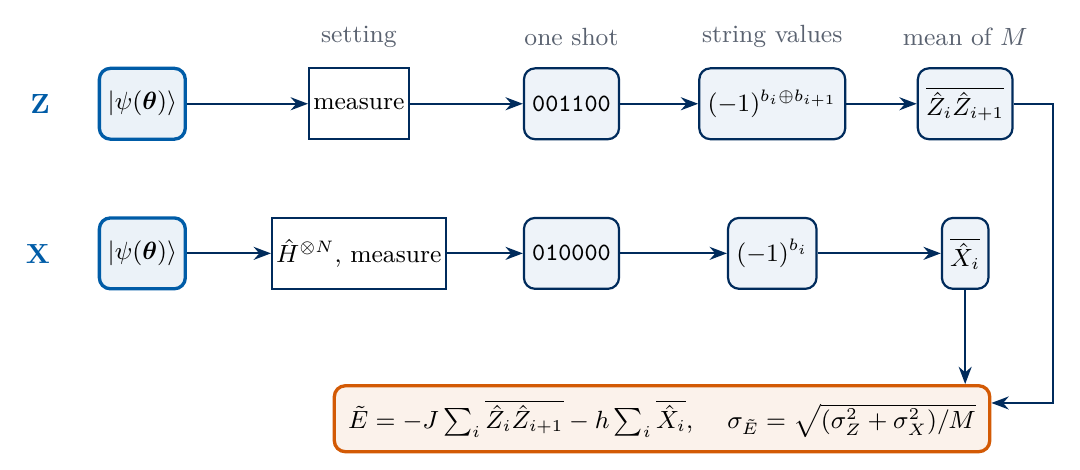

*Energy estimate from two measurement settings. Each shot gives the values of all strings of its setting, and the sample means combine into $\tilde E$ with standard error $\sigma_{\tilde E}$.*

Each shot of a setting $g$ gives one value of the part of the energy that this setting measures,
$$e_Z(\mathbf b)=-J\sum_{i=0}^{N-2}(-1)^{b_i+b_{i+1}},\qquad e_X(\mathbf b)=-h\sum_{i=0}^{N-1}(-1)^{b_i} , \tag{19}$$
and the energy is the sum of the two averages over the Born distributions,
$$E(\boldsymbol\theta)=\sum_{\mathbf b}p_Z(\mathbf b)\,e_Z(\mathbf b)+\sum_{\mathbf b}p_X(\mathbf b)\,e_X(\mathbf b) , \tag{20}$$
where $p_Z(\mathbf b)=|\langle\mathbf b|\psi\rangle|^2$ and $p_X(\mathbf b)=|\langle\mathbf b|\hat H^{\otimes N}|\psi\rangle|^2$. The code evaluates equation (20) and compares it with $\langle\psi|\hat{\mathcal H}|\psi\rangle$ from the sparse matrix at the random angles $\boldsymbol\theta_r$.

In [8]:
bits_table = np.indices((2,) * N)                                   # bits_table[q] = b_q on every basis state
zsign = jnp.asarray((-1.0) ** bits_table)                           # value (-1)^{b_q} of Z_q (or X_q after H)
E_Z_VALUES = -J * sum(zsign[i] * zsign[i + 1] for i in range(N - 1))   # e_Z(b), equation (19)
E_X_VALUES = -h * zsign.sum(axis=0)                                 # e_X(b), equation (19)

def born_z(psi):
    return jnp.abs(psi) ** 2

def born_x(psi):
    for q in range(psi.ndim):
        psi = apply_1q(psi, HAD, q)
    return jnp.abs(psi) ** 2

def energy(psi):
    # equation (20): two settings, each an average of e_g(b) over its Born distribution
    return jnp.sum(born_z(psi) * E_Z_VALUES) + jnp.sum(born_x(psi) * E_X_VALUES)

def energy_of_angles(theta):
    return energy(hea_state(theta, N, L))

E_r = float(energy(psi_r))
assert abs(E_r - expect_sparse(np.asarray(psi_r).reshape(-1))) < TOL
assert abs(float(energy(zero_state(N))) - E_zeros) < TOL
print(f"random angles: E(theta_r) = {E_r:.6f} from equation (20), {expect_sparse(np.asarray(psi_r).reshape(-1)):.6f} from the sparse matrix")
NUMBERS["EnergyRand"] = f"{E_r:.3f}"

random angles: E(theta_r) = -0.186397 from equation (20), -0.186397 from the sparse matrix


## 9. The energy from bit strings

A device returns $M$ bit strings $\mathbf b^{(1)},\dots,\mathbf b^{(M)}$ in the $z$ setting and $M$ bit strings $\mathbf b'^{(1)},\dots,\mathbf b'^{(M)}$ in the $x$ setting. The estimate of the energy replaces each average in equation (20) by the sample mean,
$$\tilde E=\frac1M\sum_{s=1}^Me_Z(\mathbf b^{(s)})+\frac1M\sum_{s=1}^Me_X(\mathbf b'^{(s)}) . \tag{21}$$
Its mean over many repetitions is the exact energy. The shots are independent, so the variance of each sample mean is $\sigma_g^2/M$, where
$$\sigma_g^2=\sum_{\mathbf b}p_g(\mathbf b)\,e_g(\mathbf b)^2-\Big(\sum_{\mathbf b}p_g(\mathbf b)\,e_g(\mathbf b)\Big)^2 \tag{22}$$
is the variance of a single shot of setting $g\in\{Z,X\}$. For one Pauli string with values $\pm1$ this is $1-\langle\hat P\rangle^2$. The two settings are measured independently, so their variances add and the standard error of the energy is
$$\sigma_{\tilde E}=\sqrt{\frac{\sigma_Z^2+\sigma_X^2}{M}} . \tag{23}$$
A device does not know $\sigma_g^2$ and replaces it by the sample variance of its recorded values, which is what `energy_estimate` returns as the error bar. The code draws bit strings from the two Born distributions at the angles $\boldsymbol\theta_r$ by inverse-transform sampling, in which a uniform random number in $[0,1)$ selects the first basis state whose cumulative probability exceeds it. It prints a few of them with the parity that gives $\hat Z_0\hat Z_1$, and estimates the energy from $M=1000$ shots per setting.

In [9]:
@partial(jax.jit, static_argnums=2)
def sample_indices(key, p, shape):
    # basis-state indices i = sum_q b_q 2^(N-1-q) drawn from the Born distribution p:
    # a uniform number u selects the first index whose cumulative probability exceeds u
    cdf = jnp.cumsum(p.reshape(-1))
    u = jax.random.uniform(key, shape if isinstance(shape, tuple) else (shape,)) * cdf[-1]
    return jnp.minimum(jnp.searchsorted(cdf, u, method="scan_unrolled"), p.size - 1)

def index_to_bits(i, N):
    return [(int(i) >> (N - 1 - q)) & 1 for q in range(N)]

def energy_estimate(key, psi, shots):
    kz, kx = jax.random.split(key)
    vz = E_Z_VALUES.reshape(-1)[sample_indices(kz, born_z(psi), shots)]
    vx = E_X_VALUES.reshape(-1)[sample_indices(kx, born_x(psi), shots)]
    est = float(vz.mean() + vx.mean())
    se = float(np.sqrt((np.var(vz, ddof=1) + np.var(vx, ddof=1)) / shots))   # equation (23) with sample variances
    return est, se

def shot_variances(psi):
    # sigma_Z^2 and sigma_X^2 of equation (22)
    out = []
    for p, e in ((born_z(psi), E_Z_VALUES), (born_x(psi), E_X_VALUES)):
        out.append(float(jnp.sum(p * e ** 2) - jnp.sum(p * e) ** 2))
    return out

key, k = jax.random.split(key)
first = sample_indices(k, born_z(psi_r), 5)
print("five shots in the z setting:  b_0 ... b_5   value of Z_0 Z_1 = (-1)^(b_0 + b_1)")
for i in first:
    b = index_to_bits(i, N)
    print("                             ", "".join(map(str, b)), f"  {(-1) ** (b[0] + b[1]):+d}")
M_DEMO = 1000
key, k = jax.random.split(key)
E_est, E_se = energy_estimate(k, psi_r, M_DEMO)
sZ2, sX2 = shot_variances(psi_r)
print(f"estimate from {M_DEMO} shots per setting: {E_est:.3f} +- {E_se:.3f};  exact {E_r:.3f};  "
      f"prediction of equation (23): {np.sqrt((sZ2 + sX2) / M_DEMO):.3f}")
assert abs(E_est - E_r) < 4 * E_se
NUMBERS.update(ShotsDemo=f"{M_DEMO}", EnergyEst=f"{E_est:.3f}", EnergySE=f"{E_se:.3f}",
               SigmaSqZ=f"{sZ2:.2f}", SigmaSqX=f"{sX2:.2f}")

five shots in the z setting:  b_0 ... b_5   value of Z_0 Z_1 = (-1)^(b_0 + b_1)
                              111111   +1
                              101110   -1
                              110011   +1
                              001110   +1
                              011100   -1
estimate from 1000 shots per setting: -0.172 +- 0.107;  exact -0.186;  prediction of equation (23): 0.106


To test equation (23) we repeat the whole measurement 300 times with $10^4$ shots per setting, form the estimate from the first $M$ shots of each record and compare the spread of the 300 estimates with the prediction. The figure shows the standard deviation of the repeated estimates against $M$ together with equation (23).

M: [10, 30, 100, 300, 1000, 3000, 10000]
spread / prediction: [0.973, 1.027, 0.943, 1.005, 0.926, 0.929, 0.961]
shots per setting for a standard error of 0.01 J at theta_r: 1.12e+05


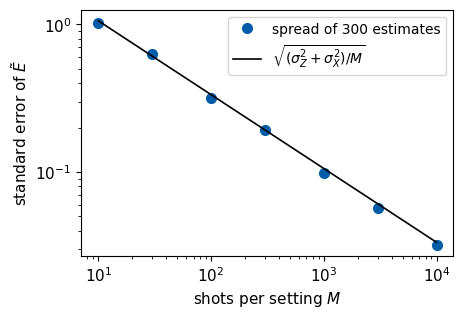

In [10]:
M_LIST = np.array([10, 30, 100, 300, 1000, 3000, 10000])
REPEATS = 300
pz_r, px_r = born_z(psi_r).reshape(-1), born_x(psi_r).reshape(-1)
key, kz, kx = jax.random.split(key, 3)
# one record of M_max shots per setting for each of the 300 repetitions; the first M shots give the estimate with M shots
vz_all = np.asarray(E_Z_VALUES.reshape(-1)[sample_indices(kz, pz_r, (REPEATS, int(M_LIST[-1])))])
vx_all = np.asarray(E_X_VALUES.reshape(-1)[sample_indices(kx, px_r, (REPEATS, int(M_LIST[-1])))])
spread = []
for M in M_LIST:
    estimates = vz_all[:, :M].mean(axis=1) + vx_all[:, :M].mean(axis=1)
    spread.append(estimates.std(ddof=1))
    assert abs(estimates.mean() - E_r) < 4 * estimates.std(ddof=1) / np.sqrt(REPEATS)    # no bias
spread = np.array(spread)
prediction = np.sqrt((sZ2 + sX2) / M_LIST)
assert np.all(np.abs(spread / prediction - 1) < 0.2)       # 300 repeats determine a spread to about 4 %
fig, ax = plt.subplots()
ax.loglog(M_LIST, spread, "o", color=COL["hea"], ms=7, label="spread of 300 estimates")
ax.loglog(M_LIST, prediction, "-", color=COL["exact"], lw=1.2, label=r"$\sqrt{(\sigma_Z^2+\sigma_X^2)/M}$")
ax.set_xlabel(r"shots per setting $M$"); ax.set_ylabel(r"standard error of $\tilde E$")
ax.legend(loc="upper right")
save(fig, "fig_lab069_shot_noise"); plt.show()
eps_target = 0.01
M_needed = (sZ2 + sX2) / eps_target ** 2
print("M:", M_LIST.tolist())
print("spread / prediction:", np.round(spread / prediction, 3).tolist())
print(f"shots per setting for a standard error of {eps_target} J at theta_r: {M_needed:.3g}")
NUMBERS["ShotsForCentiJ"] = sci(M_needed)

The measured spread follows the line $\propto M^{-1/2}$ of equation (23) over three orders of magnitude of $M$. Every tenfold reduction of the error bar costs a hundred times more shots, and a standard error of $0.01J$ at these angles needs about $10^5$ shots per setting. The single-shot variances $\sigma_g^2$ depend on the state, so the same target needs a different number of shots at other angles.

## 10. The energy along one angle

The parameter-shift rule follows from the dependence of the energy on a single angle. We split the circuit (15) at the rotation that carries $\theta_k$, $\hat U(\boldsymbol\theta)=\hat A\,e^{-i\theta_k\hat P_k/2}\,\hat B$, where $\hat B$ contains all gates before it and $\hat A$ all gates after it, and neither depends on $\theta_k$. With $|\phi\rangle=\hat B|0\dots0\rangle$ and $\hat O=\hat A^\dagger\hat{\mathcal H}\hat A$, the energy as a function of $\theta_k$ alone is
$$E(\theta_k)=\langle\phi|\,e^{i\theta_k\hat P_k/2}\,\hat O\,e^{-i\theta_k\hat P_k/2}\,|\phi\rangle . \tag{24}$$
Inserting equation (17) and multiplying out gives
$$E(\theta_k)=\cos^2\frac{\theta_k}2\,\langle\hat O\rangle+\sin^2\frac{\theta_k}2\,\langle\hat P_k\hat O\hat P_k\rangle+i\sin\frac{\theta_k}2\cos\frac{\theta_k}2\,\langle[\hat P_k,\hat O]\rangle , \tag{25}$$
with all expectation values in $|\phi\rangle$. The half-angle identities $\cos^2(\theta/2)=(1+\cos\theta)/2$, $\sin^2(\theta/2)=(1-\cos\theta)/2$ and $2\sin(\theta/2)\cos(\theta/2)=\sin\theta$ turn this into
$$E(\theta_k)=a+\beta\cos\theta_k+\gamma\sin\theta_k=a+b\cos(\theta_k-c) , \tag{26}$$
where $a=\tfrac12(\langle\hat O\rangle+\langle\hat P_k\hat O\hat P_k\rangle)$, $\beta=\tfrac12(\langle\hat O\rangle-\langle\hat P_k\hat O\hat P_k\rangle)$, $\gamma=\tfrac i2\langle[\hat P_k,\hat O]\rangle$, the amplitude is $b=\sqrt{\beta^2+\gamma^2}$ and the phase $c$ satisfies $\cos c=\beta/b$, $\sin c=\gamma/b$. The derivation uses only $\hat P_k^2=\hat I$, so it holds for every rotation of the circuit and for every Hamiltonian.

Three energies fix the three constants, $E(0)=a+\beta$ and $E(\pm\pi/2)=a\pm\gamma$. We hold all other angles at $\boldsymbol\theta_r$, take $\theta_k$ to be the $\hat R_y$ angle of qubit 2 in block 1, determine $a$, $\beta$, $\gamma$ from these three energies and compare the cosine with the energy computed at 201 angles. A least-squares fit of $a+\beta\cos\theta_k+\gamma\sin\theta_k$ to all 201 values gives the same constants.

theta_k = angle 16: a = -0.5825, b = 0.5628, c = 1.8755
three-point cosine vs 201 computed energies: largest difference 1.3e-15
least-squares (a, beta, gamma): [-0.582476 -0.168828  0.536886]  three-point: [-0.582476 -0.168828  0.536886]


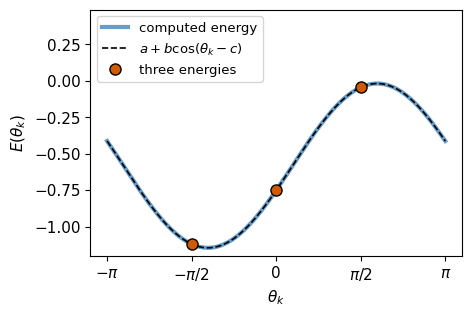

In [11]:
k_demo = 2 * (1 * N + 2) + 0                       # R_y angle of qubit 2 in block 1
energy_jit = jax.jit(energy_of_angles)
def energy_along(theta_k):
    return float(energy_jit(theta_r.at[k_demo].set(theta_k)))

grid = np.linspace(-np.pi, np.pi, 201)
scan_E = np.array(jax.jit(jax.vmap(lambda t: energy_of_angles(theta_r.at[k_demo].set(t))))(jnp.asarray(grid)))
E_0, E_p, E_m = energy_along(0.0), energy_along(np.pi / 2), energy_along(-np.pi / 2)
a = (E_p + E_m) / 2; beta = E_0 - a; gamma = (E_p - E_m) / 2
b_amp, c_phase = np.hypot(beta, gamma), np.arctan2(gamma, beta)
cosine = a + b_amp * np.cos(grid - c_phase)
design = np.stack([np.ones_like(grid), np.cos(grid), np.sin(grid)], axis=1)
coef = np.linalg.lstsq(design, scan_E, rcond=None)[0]
max_dev = float(np.max(np.abs(cosine - scan_E)))
assert max_dev < 1e-12 and np.allclose(coef, [a, beta, gamma], atol=1e-12)
print(f"theta_k = angle {k_demo}: a = {a:.4f}, b = {b_amp:.4f}, c = {c_phase:.4f}")
print(f"three-point cosine vs 201 computed energies: largest difference {max_dev:.1e}")
print("least-squares (a, beta, gamma):", np.round(coef, 6), " three-point:", np.round([a, beta, gamma], 6))
fig, ax = plt.subplots()
ax.plot(grid, scan_E, color=COL["hea"], lw=3, alpha=0.6, label="computed energy")
ax.plot(grid, cosine, "--", color=COL["exact"], lw=1.2, label=r"$a+b\cos(\theta_k-c)$")
ax.plot([0, np.pi / 2, -np.pi / 2], [E_0, E_p, E_m], "o", color=COL["hva"], ms=8, mec="black", label="three energies")
ax.set_xlabel(r"$\theta_k$"); ax.set_ylabel(r"$E(\theta_k)$")
ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi]); ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
ax.set_ylim(top=ax.get_ylim()[1] + 0.45); ax.legend(loc="upper left", fontsize=9.5)
save(fig, "fig_lab069_one_angle"); plt.show()
NUMBERS.update(CosA=f"{a:.3f}", CosB=f"{b_amp:.3f}", CosC=f"{c_phase:.3f}", CosMaxDev=sci(max_dev, 0))

The computed energy and the cosine through three points coincide at all 201 angles. Along any single angle the landscape is a shifted cosine of period $2\pi$, with one minimum and one maximum. The difficulty of the optimisation comes from the $n$ angles together, since the constants $a$, $b$ and $c$ of one angle depend on the values of all the others.

## 11. The parameter-shift rule and automatic differentiation

Differentiating equation (26) gives $\partial E/\partial\theta_k=-\beta\sin\theta_k+\gamma\cos\theta_k$. The same combination appears in the difference of two energies at angles shifted by $\pm\pi/2$,
$$E(\theta_k+\tfrac\pi2)-E(\theta_k-\tfrac\pi2)=\beta\big[\cos(\theta_k+\tfrac\pi2)-\cos(\theta_k-\tfrac\pi2)\big]+\gamma\big[\sin(\theta_k+\tfrac\pi2)-\sin(\theta_k-\tfrac\pi2)\big]=-2\beta\sin\theta_k+2\gamma\cos\theta_k . \tag{27}$$
Hence
$$\frac{\partial E}{\partial\theta_k}=\frac{E(\boldsymbol\theta+\tfrac\pi2\mathbf e_k)-E(\boldsymbol\theta-\tfrac\pi2\mathbf e_k)}{2} , \tag{28}$$
where $\mathbf e_k$ is the unit vector along angle $k$. Equation (28) is the parameter-shift rule [14,15]. The shift is finite and the formula is exact. Both energies are measured on the same device with the same circuit, with one angle changed. For a rotation implemented as a pulse of Rabi frequency $\Omega$ and duration $t_k=\theta_k/\Omega$, the two shifted circuits differ from the original only in the pulse duration, $t_k\pm\pi/(2\Omega)$. When one angle $\varphi$ enters several gates, with gate $g$ rotating by $\theta_g=c_g\varphi$ for a constant $c_g$, the chain rule gives
$$\frac{\partial E}{\partial\varphi}=\sum_gc_g\,\frac{\partial E}{\partial\theta_g} , \tag{29}$$
and each term is evaluated with the two-point rule (28) by shifting the angle of gate $g$ alone. The cost on a device therefore counts the parametrised Pauli rotations, two circuits per gate occurrence, and not the number of free angles. The mean-field state (10) is an example, with the angle $\theta$ in all $N$ gates $\hat R_y(\theta)$ and $c_g=1$, and the code checks equation (29) on it against the derivative of equation (11). The sketch shows the two shifted circuits of equation (28) and the sum of equation (29) for an angle shared by several gates.

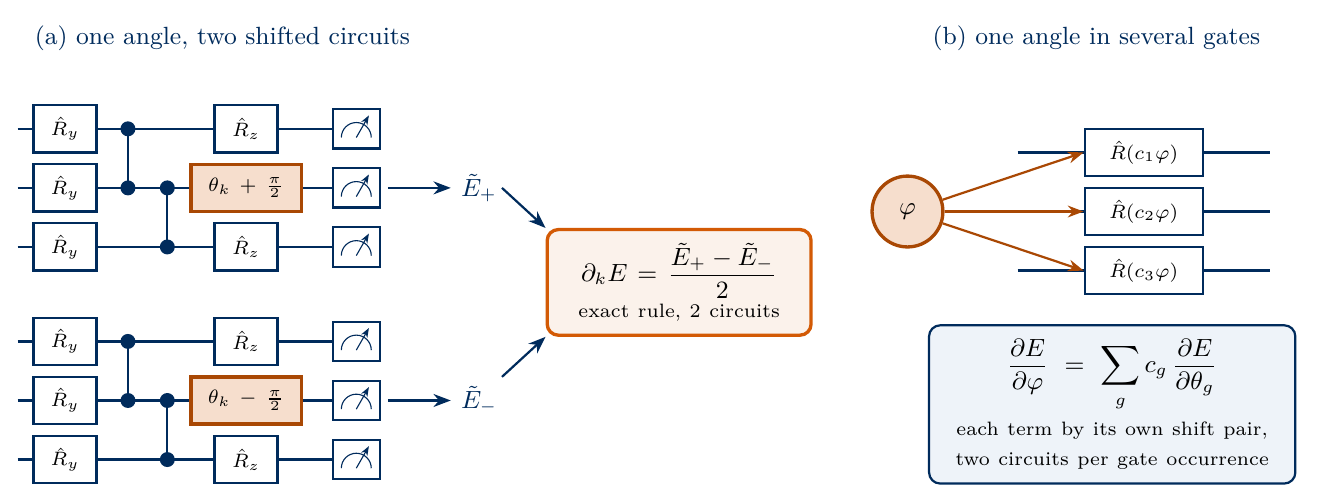

*Parameter-shift rule with two circuits whose angle $\theta_k$ is shifted by $\pm\pi/2$, and the chain rule for one angle $\varphi$ in several gates, two circuits per gate occurrence.*

A simulation holds the state vector and can differentiate the program that computes the energy. Automatic differentiation applies the chain rule to every elementary operation of that program. Its reverse mode [16], which `jax.grad` implements [17], runs the program forwards, stores the intermediate states and propagates derivatives backwards through the gates, so that the whole gradient costs a few energy evaluations for any $n$. A device has no access to the intermediate states, and for hardware the parameter-shift rule is the exact method. The code evaluates equation (28) for all 60 angles, with the $2n=120$ shifted energies computed in one vectorised call, and compares the result with `jax.grad`.

In [12]:
def parameter_shift_gradient(theta):
    shifts = (jnp.pi / 2) * jnp.eye(theta.size)
    e_plus = jax.vmap(energy_of_angles)(theta + shifts)      # n circuits with theta_k + pi/2
    e_minus = jax.vmap(energy_of_angles)(theta - shifts)     # n circuits with theta_k - pi/2
    return (e_plus - e_minus) / 2                            # equation (28)

grad_ps_fn = jax.jit(parameter_shift_gradient)
grad_ad_fn = jax.jit(jax.grad(energy_of_angles))
g_ps = grad_ps_fn(theta_r); g_ad = grad_ad_fn(theta_r)
diff = float(jnp.max(jnp.abs(g_ps - g_ad)))
assert diff < 1e-12
assert abs(float(g_ad[k_demo]) - (-beta * np.sin(theta_r[k_demo]) + gamma * np.cos(theta_r[k_demo]))) < 1e-12
t0 = time.perf_counter(); [grad_ps_fn(theta_r).block_until_ready() for _ in range(20)]; t_ps = (time.perf_counter() - t0) / 20
t0 = time.perf_counter(); [grad_ad_fn(theta_r).block_until_ready() for _ in range(20)]; t_ad = (time.perf_counter() - t0) / 20
t0 = time.perf_counter(); [energy_jit(theta_r).block_until_ready() for _ in range(20)]; t_e = (time.perf_counter() - t0) / 20
print(f"largest |parameter shift - jax.grad| over all {n} components: {diff:.1e}")
print(f"time per gradient: parameter shift {1e3 * t_ps:.2f} ms (2n = {2 * n} energies), jax.grad {1e3 * t_ad:.2f} ms, "
      f"one energy {1e3 * t_e:.2f} ms")
NUMBERS["ShiftMaxDiff"] = sci(diff, 0)
# equation (29) on the mean-field state: one angle in the N gates R_y(theta), c_g = 1, 2N shifted circuits
energy_L0 = lambda t: energy(hea_state(t, N, 0))
th_mf0 = 0.7
t_mf = jnp.stack([jnp.full(N, th_mf0), jnp.zeros(N)], axis=1).reshape(-1)
d_chain = sum((energy_L0(t_mf.at[2 * q].add(np.pi / 2)) - energy_L0(t_mf.at[2 * q].add(-np.pi / 2))) / 2 for q in range(N))
d_exact = np.cos(th_mf0) * (2 * J * (N - 1) * np.sin(th_mf0) - h * N)
assert abs(float(d_chain) - d_exact) < 1e-12
print(f"shared angle in {N} gates: chain rule with {2 * N} shifted circuits {float(d_chain):.6f}, derivative of equation (11) {d_exact:.6f}")

largest |parameter shift - jax.grad| over all 60 components: 1.1e-15
time per gradient: parameter shift 4.64 ms (2n = 120 energies), jax.grad 0.46 ms, one energy 0.11 ms
shared angle in 6 gates: chain rule with 12 shifted circuits 0.338196, derivative of equation (11) 0.338196


The two gradients agree to numerical precision in all 60 components. In the simulation `jax.grad` costs a few energy evaluations, whereas the parameter-shift rule evaluates $2n$ circuits, and the difference grows with $n$. The measured times depend on the computer and on vectorisation, and serve only to compare the two methods on the same machine.

## 12. The cost of a gradient on a device

On a device each energy in equation (28) is itself an estimate from bit strings. One gradient requires $2n$ circuits, each measured in $G$ settings with $M$ shots, which is
$$\text{shots per gradient}=2n\,G\,M . \tag{30}$$
For the six-qubit chain with $L=4$ we have $n=60$ and $G=2$, and $M=1000$ shots per setting gives 240 000 shots for a single gradient. A training run of 600 gradient steps then needs about $1.4\times10^8$ shots, and the number grows linearly with the number of angles and with the number of settings of the Hamiltonian.

Two other gradient estimates are common. Central finite differences $[E(\boldsymbol\theta+\epsilon\mathbf e_k)-E(\boldsymbol\theta-\epsilon\mathbf e_k)]/(2\epsilon)$ need the same $2n$ circuits, and the shot noise of the two energies is divided by the small step $\epsilon$, so the error of the derivative grows as $1/\epsilon$. Simultaneous-perturbation stochastic approximation (SPSA) [18] shifts all angles at once along a random direction with entries $\pm1$ and needs two energies per step for any $n$. Its estimate is a random vector whose average over the directions is the gradient.

In [13]:
G_SETTINGS, M_SHOTS, TRAIN_STEPS = 2, 1000, 600
shots_per_gradient = 2 * n * G_SETTINGS * M_SHOTS
print(f"n = {n} angles, 2n = {2 * n} circuits, G = {G_SETTINGS} settings, M = {M_SHOTS} shots")
print(f"shots per gradient, equation (30): {shots_per_gradient:,}")
print(f"shots for {TRAIN_STEPS} gradient steps: {shots_per_gradient * TRAIN_STEPS:.2e}")
NUMBERS.update(GradCircuits=f"{2 * n}", GradShots=f"{shots_per_gradient}", TrainShots=sci(shots_per_gradient * TRAIN_STEPS),
               TrainSteps=f"{TRAIN_STEPS}")

n = 60 angles, 2n = 120 circuits, G = 2 settings, M = 1000 shots
shots per gradient, equation (30): 240,000
shots for 600 gradient steps: 1.44e+08


## 13. Training the circuit

With the gradient available, the angles are updated by gradient descent, $\boldsymbol\theta\leftarrow\boldsymbol\theta-\eta\nabla E(\boldsymbol\theta)$ with a step size $\eta$. We use Adam [19], a variant of gradient descent that scales the step of each angle with running averages of its past gradients and of their squares. The few lines of the update are written out in the code, with step size $0.05$ and the standard averaging constants of Ref. [19]. The gradients are exact, from `jax.grad`, and the 600 steps run inside one compiled `jax.lax.scan`. The initial angles are drawn uniformly from $[-0.1,0.1]$, so the circuit starts close to the product state $|0\dots0\rangle$ with energy $-J(N-1)$. After training we compare the energy with $E_0$ and compute the fidelity $F=|\langle E_0|\psi(\boldsymbol\theta)\rangle|^2$ with the exact ground state, which only a simulation can do.

the energy falls below E_1 at step 17
after 600 Adam steps: E = -7.28909, E_0 = -7.29623, relative error 9.8e-04, fidelity 0.9977
equation (2): E - E_0 = 0.0071 >= gap x (1 - F) = 0.0011


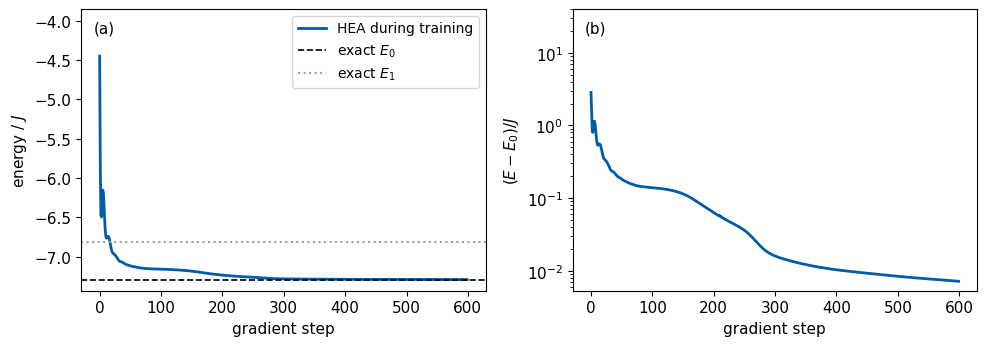

In [14]:
value_and_grad = jax.value_and_grad(energy_of_angles)

@jax.jit
def train_adam(theta0, lr=0.05, b1=0.9, b2=0.999, eps=1e-8):
    def step(carry, t):
        theta, m, v = carry
        E, g = value_and_grad(theta)
        m = b1 * m + (1 - b1) * g                  # running average of the gradient
        v = b2 * v + (1 - b2) * g ** 2             # running average of its square
        m_hat, v_hat = m / (1 - b1 ** (t + 1)), v / (1 - b2 ** (t + 1))
        return (theta - lr * m_hat / (jnp.sqrt(v_hat) + eps), m, v), E
    zeros = jnp.zeros_like(theta0)
    (theta, _, _), history = jax.lax.scan(step, (theta0, zeros, zeros), jnp.arange(TRAIN_STEPS))
    return theta, history

key, k = jax.random.split(key)
theta0 = jax.random.uniform(k, (n,), minval=-0.1, maxval=0.1)
theta_opt, history = train_adam(theta0)
history = np.asarray(history)
E_final = float(energy_of_angles(theta_opt))
psi_opt = np.asarray(hea_state(theta_opt, N, L)).reshape(-1)
fidelity = float(abs(np.vdot(psi_ground, psi_opt)) ** 2)
rel_err = (E_final - E0) / abs(E0)
assert E_final >= E0 - TOL                                  # equation (1)
assert E_final - E0 >= (E1 - E0) * (1 - fidelity) - 1e-10   # equation (2)
assert rel_err < 5e-3
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
ax1.plot(np.arange(TRAIN_STEPS), history, color=COL["hea"], lw=2, label="HEA during training")
ax1.axhline(E0, color=COL["exact"], ls="--", lw=1.2, label=r"exact $E_0$")
ax1.axhline(E1, color=COL["rand"], ls=":", lw=1.5, label=r"exact $E_1$")
ax1.set_xlabel("gradient step"); ax1.set_ylabel(r"energy / $J$"); ax1.set_ylim(top=-3.85); ax1.legend(loc="upper right")
ax2.semilogy(np.arange(TRAIN_STEPS), history - E0, color=COL["hea"], lw=2)
ax2.set_xlabel("gradient step"); ax2.set_ylabel(r"$(E-E_0)/J$"); ax2.set_ylim(top=40)
for ax, lab in ((ax1, "(a)"), (ax2, "(b)")):
    ax.text(0.03, 0.96, lab, transform=ax.transAxes, va="top", fontsize=11)
fig.tight_layout()
save(fig, "fig_lab069_training"); plt.show()
below_E1 = int(np.argmax(history < E1))
print(f"the energy falls below E_1 at step {below_E1}")
print(f"after {TRAIN_STEPS} Adam steps: E = {E_final:.5f}, E_0 = {E0:.5f}, relative error {rel_err:.1e}, fidelity {fidelity:.4f}")
print(f"equation (2): E - E_0 = {E_final - E0:.4f} >= gap x (1 - F) = {(E1 - E0) * (1 - fidelity):.4f}")
NUMBERS.update(InitialEnergy=f"{history[0]:.2f}", StepBelowEOne=f"{below_E1}", FinalEnergy=f"{E_final:.4f}", FinalRelErr=sci(rel_err, 0), FinalFidelity=f"{fidelity:.3f}")

The energy starts at about $-4.5$, close to the value $-5$ of $|0\dots0\rangle$, falls below the first excited level $E_1$ within the first twenty steps and then approaches $E_0$ slowly, as panel (b) with the logarithmic scale shows. The final relative error of the energy is of order $10^{-3}$ and the fidelity with the exact ground state is close to one, consistent with the bound (2). This run used exact gradients and therefore shows only that the loop works with this ansatz. On a device the same 600 steps would cost the shots counted in Section 12, and the comparison of different ansätze is a separate question. The core route ends here.

## 14. A gradient from bit strings

At home, we replace the exact energies in equation (28) by the estimates (21). Each component of the gradient is then $\tilde g_k=(\tilde E_{k,+}-\tilde E_{k,-})/2$, with two independent energy estimates. By equation (23) its standard error is
$$\sigma_{\tilde g_k}=\frac12\sqrt{\sigma_{\tilde E_{k,+}}^2+\sigma_{\tilde E_{k,-}}^2}\approx\sqrt{\frac{\sigma^2}{2M}} , \tag{31}$$
where $\sigma^2=\sigma_Z^2+\sigma_X^2$ is the single-shot variance of the energy at the shifted angles, close to its value at $\boldsymbol\theta_r$. The code estimates all 60 components at the random angles $\boldsymbol\theta_r$ with $M=1000$ shots per setting and per shifted circuit, 240 000 shots in total, and compares them with the exact gradient. If the error bars are right, the normalised deviations $z_k=(\tilde g_k-\partial_kE)/\sigma_{\tilde g_k}$ have a mean square that fluctuates around one, by about $\sqrt{2/60}\approx0.18$ for 60 components, and we average it over 20 further records to test this.

standard error per component: 0.067 to 0.077  (sqrt(sigma^2 / 2M) at theta_r: 0.075)
mean of z_k^2 over 60 components: 1.41 for this record, 1.04 on average over 20 further records;  components with |exact| > 2 standard errors: 42 of 60


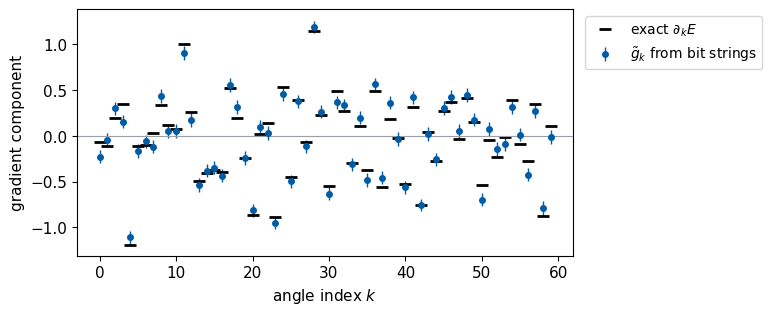

In [15]:
@partial(jax.jit, static_argnums=2)
def shot_gradient_device(key, theta, shots):
    shifts = (jnp.pi / 2) * jnp.eye(theta.size)
    states = jax.vmap(lambda t: hea_state(t, N, L))(jnp.concatenate([theta + shifts, theta - shifts]))
    pz = jax.vmap(born_z)(states).reshape(2 * theta.size, -1)
    px = jax.vmap(born_x)(states).reshape(2 * theta.size, -1)
    kz, kx = jax.random.split(key)
    keys_z, keys_x = jax.random.split(kz, 2 * theta.size), jax.random.split(kx, 2 * theta.size)
    iz = jax.vmap(sample_indices, in_axes=(0, 0, None))(keys_z, pz, shots)
    ix = jax.vmap(sample_indices, in_axes=(0, 0, None))(keys_x, px, shots)
    vz, vx = E_Z_VALUES.reshape(-1)[iz], E_X_VALUES.reshape(-1)[ix]
    E_tilde = vz.mean(axis=1) + vx.mean(axis=1)                                  # equation (21), 2n circuits
    var_E = (vz.var(axis=1, ddof=1) + vx.var(axis=1, ddof=1)) / shots            # equation (23) squared
    g = (E_tilde[:n] - E_tilde[n:]) / 2
    se = 0.5 * jnp.sqrt(var_E[:n] + var_E[n:])                                   # equation (31)
    return g, se

def shot_gradient(key, theta, shots):
    g, se = shot_gradient_device(key, theta, shots)
    return np.asarray(g), np.asarray(se)

key, k = jax.random.split(key)
g_tilde, g_se = shot_gradient(k, theta_r, M_SHOTS)
g_exact = np.asarray(g_ad)
zk = (g_tilde - g_exact) / g_se
mean_z2 = float(np.mean(zk ** 2))
mean_z2_records = []
for _ in range(20):                                # 20 further independent records of 240 000 shots each
    key, k = jax.random.split(key)
    g_, se_ = shot_gradient(k, theta_r, M_SHOTS)
    mean_z2_records.append(float(np.mean(((g_ - np.asarray(g_ad)) / se_) ** 2)))
mean_z2_avg = float(np.mean(mean_z2_records))
assert 0.85 < mean_z2_avg < 1.15                   # each record fluctuates by about sqrt(2/60) = 0.18 around one
resolved = int(np.sum(np.abs(g_exact) > 2 * g_se))
idx = np.arange(n)
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.errorbar(idx, g_tilde, yerr=g_se, fmt="o", ms=4, color=COL["hea"], elinewidth=1, label=r"$\tilde g_k$ from bit strings")
ax.plot(idx, g_exact, "_", ms=9, mew=2, color=COL["exact"], label=r"exact $\partial_kE$")
ax.axhline(0, color=COL["rand"], lw=0.8)
ax.set_xlabel(r"angle index $k$"); ax.set_ylabel("gradient component")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
save(fig, "fig_lab069_shot_gradient"); plt.show()
print(f"standard error per component: {g_se.min():.3f} to {g_se.max():.3f}  (sqrt(sigma^2 / 2M) at theta_r: {np.sqrt((sZ2 + sX2) / (2 * M_SHOTS)):.3f})")
print(f"mean of z_k^2 over {n} components: {mean_z2:.2f} for this record, {mean_z2_avg:.2f} on average over 20 further records;  components with |exact| > 2 standard errors: {resolved} of {n}")
NUMBERS.update(ShotGradSE=f"{np.median(g_se):.3f}", ShotGradMeanZsq=f"{mean_z2:.2f}", ShotGradMeanZsqAvg=f"{mean_z2_avg:.2f}", ShotGradResolved=f"{resolved}")

The estimated components scatter around the exact ones within their error bars. The mean square of the normalised deviations averages to one over many records, so equation (31) describes the noise of the gradient. Components whose exact value is smaller than about twice the error bar cannot be told apart from zero with this number of shots. Halving the error bar requires four times as many shots, and when the gradient components of a circuit are small, the number of shots needed to resolve them grows as the inverse square of their size.

## Appendix (at home, optional). Mean field for bosons, tensor networks and Monte Carlo

This appendix lies outside the classroom route, and no cell of the core route uses its results. Part A applies the mean-field idea of Section 4 to bosons in a trap, where it gives the Gross–Pitaevskii equation, and compares the two families of mean-field theory. Part B describes in two paragraphs how tensor networks and Monte Carlo methods approximate many-body states and where each of them fails.

### A. Bosons in a trap and the Gross–Pitaevskii equation

The mean-field logic of Section 4 applies equally to identical bosons, such as the atoms of a Bose–Einstein condensate held in a trap. In mean-field theory all $N$ bosons occupy the same normalised single-particle wave function $\phi(x)$, so the many-body wave function is the product $\phi(x_1)\cdots\phi(x_N)$ and the bosons are uncorrelated. For bosons of mass $m$ in a trap potential $V(x)$, which interact with strength $g$ when two of them are at the same point, minimising the energy of this product over $\phi$ gives
$$\Big[-\frac{\hbar^2}{2m}\frac{d^2}{dx^2}+V(x)+g(N-1)\,|\phi(x)|^2\Big]\phi(x)=\mu\,\phi(x) , \tag{4}$$
the Gross–Pitaevskii equation [2,3]. It has the form of a Schrödinger equation in which the trap potential is supplemented by the mean interaction energy $g(N-1)|\phi(x)|^2$ that one boson feels from the other $N-1$. This potential depends on the solution itself, so the equation is nonlinear and has to be solved self-consistently. Its eigenvalue $\mu$ is the chemical potential, the energy needed to add one more boson to the condensate. The sketch shows this picture for bosons in a trap, next to the spin chain of Section 4, in which every spin takes the same state.

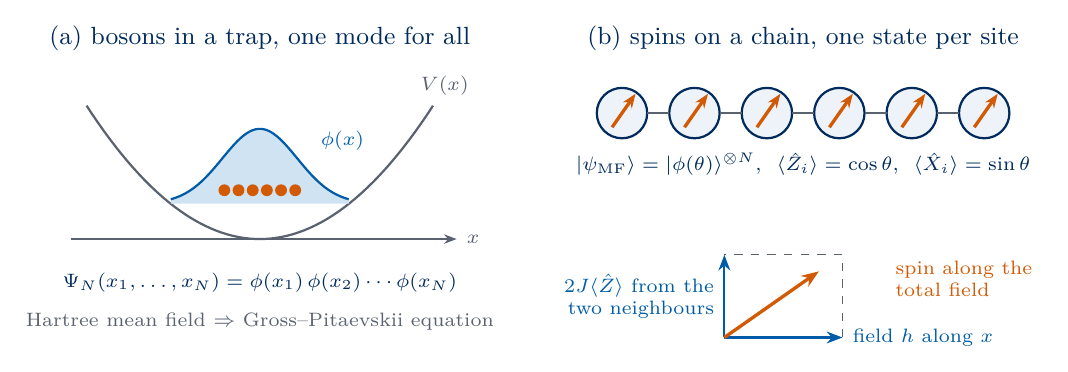

*Mean field for bosons in a trap, all in one mode $\phi(x)$, and for spins on a chain, all in the same state $|\phi(\theta)\rangle$ aligned with the total field.*

#### Derivation of the Gross–Pitaevskii equation (optional)

Many identical bosons are described most easily by counting how many of them occupy each single-particle state. A single boson in the trap has orthonormal wave functions $\phi_i(x)$, its modes. The mode operator $\hat a_i^\dagger$ adds one boson to mode $i$ and $\hat a_i$ removes one, with $\hat a_i|n_i\rangle=\sqrt{n_i}\,|n_i-1\rangle$ on a state with $n_i$ bosons in the mode, and these operators satisfy
$$[\hat a_i,\hat a_j^\dagger]=\delta_{ij},\qquad[\hat a_i,\hat a_j]=0 . \tag{5}$$
The field operator $\hat\psi(x)=\sum_i\phi_i(x)\,\hat a_i$ expresses the mode operators in position space. It removes one boson at the position $x$, whichever mode the boson occupies, and $\hat\psi^\dagger(x)\hat\psi(x)$ is the operator of the particle density. In terms of the field operator the Hamiltonian in one dimension is
$$\hat{\mathcal H}_B=\int dx\,\hat\psi^\dagger(x)\Big[-\frac{\hbar^2}{2m}\frac{d^2}{dx^2}+V(x)\Big]\hat\psi(x)+\frac g2\int dx\,\hat\psi^\dagger(x)\hat\psi^\dagger(x)\hat\psi(x)\hat\psi(x) . \tag{6}$$
The first term is the kinetic and potential energy of every boson, and the second term counts the interaction energy of every pair of bosons at the same position.

The mean-field ansatz puts all $N$ bosons into one normalised mode $\phi(x)$, $\int dx\,|\phi(x)|^2=1$, which we choose as the first mode of the basis,
$$|\Psi_N\rangle=\frac{(\hat a_\phi^\dagger)^N}{\sqrt{N!}}\,|0\rangle , \tag{7}$$
where $|0\rangle$ here denotes the state without bosons. Its wave function is the product $\phi(x_1)\cdots\phi(x_N)$. To evaluate the energy (6) in this state we need the action of the field operator on it. Only the component $\phi(x)\hat a_\phi$ of the field operator acts on $|\Psi_N\rangle$ without giving zero, so $\hat\psi(x)|\Psi_N\rangle=\sqrt N\,\phi(x)|\Psi_{N-1}\rangle$ and $\hat\psi(x)\hat\psi(x)|\Psi_N\rangle=\sqrt{N(N-1)}\,\phi(x)^2|\Psi_{N-2}\rangle$. The two expectation values that enter the energy follow,
$$\langle\hat\psi^\dagger(x)\hat\psi(x')\rangle=N\,\phi^*(x)\,\phi(x'),\qquad\langle\hat\psi^\dagger(x)\hat\psi^\dagger(x)\hat\psi(x)\hat\psi(x)\rangle=N(N-1)\,|\phi(x)|^4 , \tag{8}$$
and inserting them into equation (6) turns the energy into a functional of the single mode,
$$E[\phi]=N\int dx\,\phi^*(x)\Big[-\frac{\hbar^2}{2m}\frac{d^2}{dx^2}+V(x)\Big]\phi(x)+\frac{gN(N-1)}2\int dx\,|\phi(x)|^4 . \tag{9}$$
The energy now depends on the values of $\phi(x)$ at every point $x$, and its minimum is found as for a function of many variables, by setting the derivative with respect to each $\phi^*(x)$ to zero. The normalisation of $\phi$ is a constraint, which a Lagrange multiplier $\mu$ enforces. We therefore set to zero the functional derivative of $E[\phi]-N\mu\big(\int dx\,|\phi|^2-1\big)$ with respect to $\phi^*(x)$, treating $\phi$ and $\phi^*$ as independent variables. The derivative of $|\phi|^4=(\phi^*)^2\phi^2$ is $2|\phi|^2\phi$, and after division by $N$ the condition is the Gross–Pitaevskii equation (4).

#### The ground state in a harmonic trap

We solve equation (4) in units $\hbar=m=\omega=1$ for the harmonic trap $V(x)=x^2/2$ with frequency $\omega$, for the interaction strengths $g'=g(N-1)=0$, 10 and 50. Replacing the time $t$ by $-i\tau$ in the Schrödinger equation damps each eigencomponent by $e^{-E\tau}$. Evolution in imaginary time is therefore a relaxation, in which components of higher energy decay faster than the lowest one. Repeated small steps, each followed by normalisation, converge to the ground state from any starting state that overlaps with it. Each step multiplies by the potential and the nonlinear term in position space and by the kinetic energy in momentum space, which a fast Fourier transform reaches (the split-step method). For $g'=0$ the result must be the oscillator ground state $\pi^{-1/4}e^{-x^2/2}$ with $\mu=1/2$. For strong interactions the kinetic energy is small compared with the interaction, and equation (4) without the kinetic term gives the Thomas–Fermi density $|\phi(x)|^2=(\mu-x^2/2)/g'$ inside the cloud, an inverted parabola whose normalisation fixes $\mu_{\mathrm{TF}}=(3g'/4\sqrt2)^{2/3}$.

g(N-1) =    0: chemical potential mu = 0.5000
g(N-1) =   10: chemical potential mu = 3.1099
g(N-1) =   50: chemical potential mu = 8.9457
Thomas-Fermi for g(N-1) = 50: mu_TF = 8.8922, cloud radius sqrt(2 mu_TF) = 4.22
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


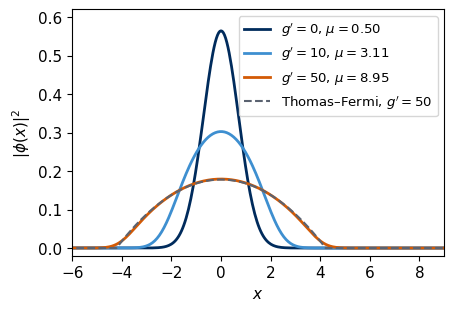

In [4]:
xg = np.linspace(-12, 12, 512, endpoint=False); dxg = xg[1] - xg[0]
kg = 2 * np.pi * np.fft.fftfreq(xg.size, dxg)
Vg = xg ** 2 / 2

def gp_chemical_potential(phi, gp):
    kinetic = np.fft.ifft(kg ** 2 / 2 * np.fft.fft(phi))
    return float(np.real(np.sum(phi.conj() * kinetic) * dxg + np.sum((Vg + gp * np.abs(phi) ** 2) * np.abs(phi) ** 2) * dxg))

def gp_ground_state(gp, steps=4000, dtau=0.005):
    # imaginary-time split-step evolution of equation (4), normalised after every step
    phi = np.exp(-xg ** 2 / 2).astype(complex); phi /= np.sqrt(np.sum(np.abs(phi) ** 2) * dxg)
    kinetic_step = np.exp(-dtau * kg ** 2 / 2)
    for _ in range(steps):
        phi = phi * np.exp(-dtau / 2 * (Vg + gp * np.abs(phi) ** 2))
        phi = np.fft.ifft(kinetic_step * np.fft.fft(phi))
        phi = phi * np.exp(-dtau / 2 * (Vg + gp * np.abs(phi) ** 2))
        phi /= np.sqrt(np.sum(np.abs(phi) ** 2) * dxg)
    return phi, gp_chemical_potential(phi, gp)

gp_results = {}
for gp in (0.0, 10.0, 50.0):
    phi, mu = gp_ground_state(gp)
    assert abs(np.sum(np.abs(phi) ** 2) * dxg - 1) < 1e-12
    gp_results[gp] = (np.abs(phi) ** 2, mu)
gauss = np.pi ** -0.25 * np.exp(-xg ** 2 / 2)
assert abs(gp_results[0.0][1] - 0.5) < 1e-6
assert np.max(np.abs(gp_results[0.0][0] - gauss ** 2)) < 1e-5
mu_tf = (3 * 50.0 / (4 * np.sqrt(2))) ** (2 / 3)
density_tf = np.maximum(mu_tf - xg ** 2 / 2, 0) / 50.0
assert abs(gp_results[50.0][1] - mu_tf) / mu_tf < 0.05
for gp, (_, mu) in gp_results.items():
    print(f"g(N-1) = {gp:4.0f}: chemical potential mu = {mu:.4f}")
print(f"Thomas-Fermi for g(N-1) = 50: mu_TF = {mu_tf:.4f}, cloud radius sqrt(2 mu_TF) = {np.sqrt(2 * mu_tf):.2f}")
fig, ax = plt.subplots()
for (gp, (dens, mu)), col in zip(gp_results.items(), (COL["navy"], COL["data"], COL["hva"])):
    ax.plot(xg, dens, color=col, lw=2, label=rf"$g'={gp:.0f}$, $\mu={mu:.2f}$")
ax.plot(xg, density_tf, "--", color=COL["mf"], lw=1.5, label=r"Thomas–Fermi, $g'=50$")
ax.set_xlim(-6, 9); ax.set_ylim(-0.02, 0.62); ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$|\phi(x)|^2$")
ax.legend(loc="upper right", fontsize=9.5)
save(fig, "fig_lab069_gross_pitaevskii"); plt.show()
NUMBERS.update(GPMuZero=f"{gp_results[0.0][1]:.3f}", GPMuTen=f"{gp_results[10.0][1]:.2f}", GPMuFifty=f"{gp_results[50.0][1]:.2f}",
               GPMuTF=f"{mu_tf:.2f}")

Without interactions the condensate occupies the Gaussian ground state of the oscillator. Repulsion spreads the cloud and lowers its central density, and at $g(N-1)=50$ the density is close to the Thomas–Fermi parabola, with deviations only at the edge of the cloud, where the kinetic energy matters. The chemical potential grows with the interaction, since each boson feels the mean repulsion of all others.

The two examples belong to two families of mean-field theory. The Gross–Pitaevskii state (7) factorises over particles, since all $N$ bosons occupy one mode. It is a Hartree mean field, in which each particle moves in the average potential created by all the others. The spin state (10) factorises over lattice sites, $|\psi\rangle=\bigotimes_i|\phi_i\rangle$, and each factor is a spin pointing in a definite direction of its Bloch sphere, so the product is a spin coherent state. It is the mean field of magnetism, in which each spin aligns with the average field of its neighbours, the molecular field that Weiss introduced for ferromagnets. Our example takes the same state on every site, and a different angle $\theta_i$ on each site is the subject of Exercise 1. For bosons on a lattice the site-factorised idea gives the Gutzwiller ansatz $|\Psi\rangle=\prod_i\sum_nf_n^{(i)}|n\rangle_i$ [5], a product over sites of superpositions of occupation numbers $n$. The Bose–Hubbard model describes bosons that hop between neighbouring sites of a lattice and repel each other on the same site. As the repulsion grows, its ground state changes from a superfluid to a Mott insulator, with a fixed number of bosons on every site [6]. The Gutzwiller ansatz describes this transition in mean field [7], whereas a single-mode Gross–Pitaevskii state cannot describe it. Neither family contains entanglement between its factors. The sketch contrasts the two factorisations, over particles and over lattice sites.

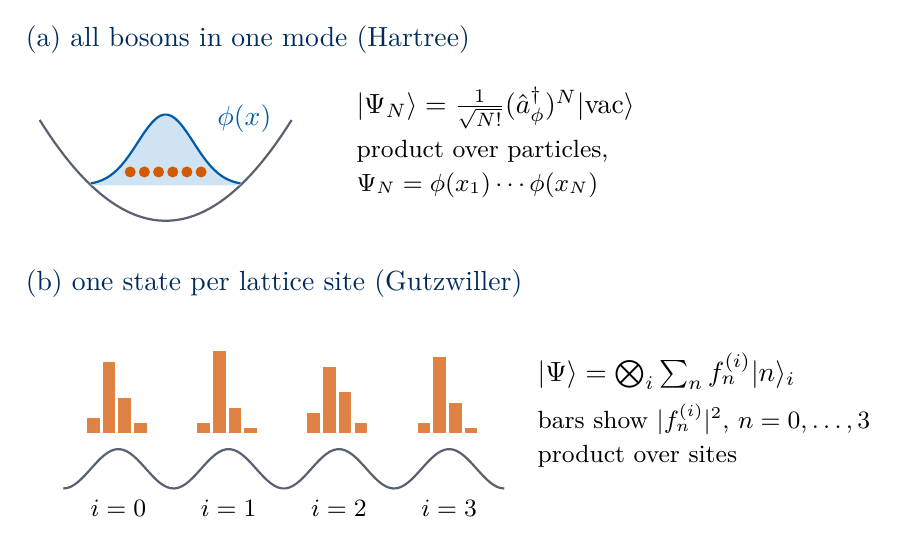

*Hartree mean field with all bosons in one mode, and the Gutzwiller ansatz with one superposition of occupation numbers on every lattice site.*

### B. Tensor networks and Monte Carlo methods

Tensor networks store a many-body state with a number of parameters that grows polynomially with $N$. A matrix product state (MPS) writes each amplitude $\psi(b_0,\dots,b_{N-1})$ as a product of $N$ matrices, one for each spin and each value of its bit, of size at most $\chi\times\chi$, where $\chi$ is the bond dimension. The MPS stores about $2N\chi^2$ numbers, and the entanglement entropy across any cut of the chain is at most $\log_2\chi$. Ground states of gapped one-dimensional Hamiltonians with local interactions obey an area law, with an entanglement entropy that stays bounded as $N$ grows, so a modest $\chi$ describes them accurately. The density-matrix renormalisation group (DMRG) optimises such states variationally [8]. The required $\chi$ grows exponentially with the entanglement that must be represented, which grows with the width of two-dimensional systems and linearly in time after a sudden change of the Hamiltonian. The sketch shows a matrix product state of six spins and a cut through the middle of the chain.

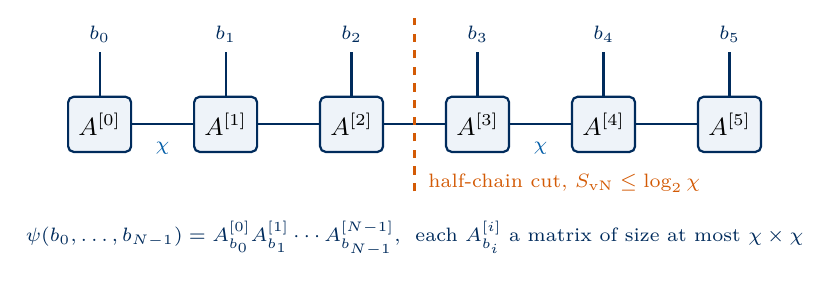

*Matrix product state of six spins. Each amplitude is a product of matrices of size at most $\chi\times\chi$, and the entanglement across any cut is at most $\log_2\chi$.*

Monte Carlo methods estimate expectation values from random samples and never store the full state. Quantum Monte Carlo maps the quantum problem onto the sampling of classical configurations with non-negative weights. For fermions and frustrated magnets the weights take both signs, and the statistical error then grows exponentially with the system size and the inverse temperature. This sign problem is NP-hard in general, which means that an efficient general solution would solve every problem of the complexity class NP efficiently [9]. Variational Monte Carlo samples bit strings $\mathbf b$ from $|\psi(\mathbf b)|^2$ of a trial wave function whose amplitudes are computed by a classical formula, and a neural network can serve as this formula, with its weights trained to minimise the energy [10]. Every classical method thus restricts the states it can represent, by their entanglement, by the sign structure of their amplitudes, or by the form of the trial wave function. The sketch shows a Markov chain of bit strings, the histogram of visits that it produces, and weights of both signs that cancel in the sign problem.

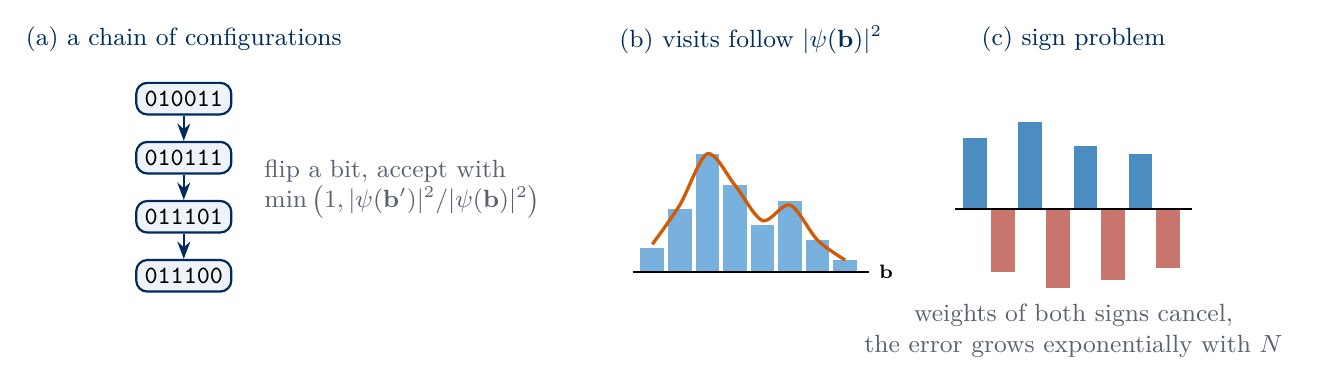

*Monte Carlo sampling of bit strings, with visits distributed as $|\psi(\mathbf b)|^2$, and the cancellation of weights of both signs that causes the sign problem.*

## Saving the results

The last code cell stores the numbers of this notebook, including those of the appendix, as LaTeX macros and a JSON summary and prints the runtime. It reads results of every code cell above it, so run the appendix before it.

In [16]:
summary = dict(
    experiment="TFIM N=6, J=h=1, open chain; HEA L=4; exact state-vector simulation and simulated bit strings",
    gross_pitaevskii=dict(g_N_minus_1=[0, 10, 50], mu=[gp_results[g][1] for g in (0.0, 10.0, 50.0)], mu_thomas_fermi=mu_tf),
    E0=E0, E1=E1, mean_field=dict(h=float(h), sin_theta=float(np.sin(theta_star)), energy=float(E_mf_h1), x_exact=float(x_ex1), zz_exact=float(zz_ex1),
                                  h_grid=h_grid.tolist(), energy_per_spin=(E_mf / N).tolist(), exact_N6=exact[6].tolist(), exact_infinite=e_inf.tolist(), mean_field_infinite=e_mf_inf.tolist(),
                                  bulk_check=[dict(h=a_, ed_bulk=b_, eq14=c_) for a_, b_, c_ in bulk_check]),
    energy_random_angles=E_r, energy_estimate=dict(shots_per_setting=M_DEMO, estimate=E_est, se=E_se),
    shot_variances=dict(sigma2_Z=sZ2, sigma2_X=sX2), shots_list=M_LIST.tolist(), spread=spread.tolist(), prediction=prediction.tolist(),
    one_angle=dict(index=k_demo, a=a, b=float(b_amp), c=float(c_phase), max_deviation=max_dev),
    parameter_shift_vs_autodiff_max_diff=diff, shots_per_gradient=shots_per_gradient,
    training=dict(steps=TRAIN_STEPS, step_below_E1=below_E1, learning_rate=0.05, final_energy=E_final, relative_error=rel_err, fidelity=fidelity),
    shot_gradient=dict(shots=M_SHOTS, mean_z2=mean_z2, mean_z2_records=mean_z2_records, resolved=resolved),
    runtime_seconds=time.perf_counter() - started)
(RES / "lab069_results.json").write_text(json.dumps(summary, indent=2))
with open(FIG / "nb_numbers_lab069.tex", "w") as f:
    for k_, v_ in NUMBERS.items():
        f.write(f"\\newcommand{{\\labsixtynine{k_}}}{{{v_.strip()}}}\n")
print("numbers:", NUMBERS)
print(f"runtime {summary['runtime_seconds']:.1f} s")

numbers: {'MemTen': '16', 'MemThirty': '17', 'MemFifty': '18', 'MemMaxLaptop': '29', 'MemMaxNode': '35', 'MemMaxExa': '52', 'N': '6', 'EZero': '-7.2962', 'EOne': '-6.8141', 'Gap': '0.482', 'EZeros': '-5', 'EPlus': '-6', 'GPMuZero': '0.500', 'GPMuTen': '3.11', 'GPMuFifty': '8.95', 'GPMuTF': '8.89', 'MFEnergy': '-6.800', 'MFRelErr': '0.068', 'MFSinTheta': '0.60', 'MFX': '0.60', 'ExactX': '0.771', 'MFZZ': '0.64', 'ExactZZ': '0.534', 'MFhc': '1.667', 'EInfExactOne': '-1.2732', 'EInfMFOne': '-1.2500', 'EBulkEDOne': '-1.2722', 'L': '4', 'NParams': '60', 'EnergyRand': '-0.186', 'ShotsDemo': '1000', 'EnergyEst': '-0.172', 'EnergySE': '0.107', 'SigmaSqZ': '5.73', 'SigmaSqX': '5.44', 'ShotsForCentiJ': '1.1\\times10^{5}', 'CosA': '-0.582', 'CosB': '0.563', 'CosC': '1.875', 'CosMaxDev': '1\\times10^{-15}', 'ShiftMaxDiff': '1\\times10^{-15}', 'GradCircuits': '120', 'GradShots': '240000', 'TrainShots': '1.4\\times10^{8}', 'TrainSteps': '600', 'InitialEnergy': '-4.45', 'StepBelowEOne': '17', 'FinalEn

## 15. Exercises

1. Allow a different angle $\theta_i$ for every spin in the product state (10), minimise the energy numerically for $N=6$ and $h=J$, and compare the result with the uniform mean-field energy and with $E_0$. Explain the profile of $\theta_i$ near the ends of the open chain.
2. Add a two-qubit rotation $\hat R_{zz}(\theta)=e^{-i\theta\hat Z_0\hat Z_1/2}$ to the end of the circuit and check equations (26) and (17) for its angle.
3. Show that the single-shot variance $\sigma_Z^2$ of equation (22) vanishes in the state $|0\dots0\rangle$ and explain why the $x$ setting still has a nonzero variance there.
4. Use the fidelity of Section 13 and the gap to check equation (2), and estimate how small the energy error must be to guarantee $F\ge0.99$.
5. Implement the central finite difference with step $\epsilon$ and plot its error against $\epsilon$, once with exact energies and once with $M=1000$ shots per setting.
6. Replace the exact gradient in the training loop by the gradient from bit strings of Section 14, with $M=100$ and $M=1000$, and compare the final energies with the run of Section 13.
7. Train with $L=1,2,\dots,6$ layers and plot the final energy error against the number of angles $n$.

## 16. Summary

The state of $N$ spins needs $2^N$ amplitudes, and classical approximations restrict the trial states. Mean field keeps only product states, which misses the correlations near the critical point and places the transition at twice the exact field. Tensor networks, described in the appendix, are limited by entanglement and Monte Carlo methods by the sign problem. The variational principle makes every trial state an upper bound on the ground-state energy, and a parametrised circuit prepares the trial state directly on the qubit register, so the $2^N$ amplitudes never have to be stored. For the transverse-field Ising chain the energy follows from two measurement settings, and its estimate from $M$ shots per setting has a standard error proportional to $M^{-1/2}$, set by the single-shot variances of the two settings. Along each angle the energy is a shifted cosine, because every rotation is generated by a Pauli string with eigenvalues $\pm1$. The parameter-shift rule follows from this cosine and gives the exact derivative from two runs of the same circuit with the angle shifted by $\pm\pi/2$, a change of the pulse duration on the device. In simulation, reverse-mode automatic differentiation gives the same gradient to numerical precision at the cost of a few energy evaluations. On a device one gradient costs $2n$ circuits times the number of settings times the number of shots. A short Adam run with exact gradients brings the hardware-efficient circuit close to the exact ground state of the six-spin chain.

## References

[1] C. Lanczos, An iteration method for the solution of the eigenvalue problem of linear differential and integral operators, J. Res. Natl. Bur. Stand. **45**, 255 (1950), doi:[10.6028/jres.045.026](https://doi.org/10.6028/jres.045.026).

[2] E. P. Gross, Structure of a quantized vortex in boson systems, Nuovo Cimento **20**, 454 (1961), doi:[10.1007/BF02731494](https://doi.org/10.1007/BF02731494).

[3] L. P. Pitaevskii, Vortex lines in an imperfect Bose gas, Sov. Phys. JETP **13**, 451 (1961), [jetp.ras.ru/cgi-bin/e/index/e/13/2/p451?a=list](http://jetp.ras.ru/cgi-bin/e/index/e/13/2/p451?a=list).

[4] P. Pfeuty, The one-dimensional Ising model with a transverse field, Ann. Phys. **57**, 79 (1970), doi:[10.1016/0003-4916(70)90270-8](https://doi.org/10.1016/0003-4916(70)90270-8).

[5] M. C. Gutzwiller, Effect of correlation on the ferromagnetism of transition metals, Phys. Rev. Lett. **10**, 159 (1963), doi:[10.1103/PhysRevLett.10.159](https://doi.org/10.1103/PhysRevLett.10.159).

[6] M. P. A. Fisher, P. B. Weichman, G. Grinstein and D. S. Fisher, Boson localization and the superfluid-insulator transition, Phys. Rev. B **40**, 546 (1989), doi:[10.1103/PhysRevB.40.546](https://doi.org/10.1103/PhysRevB.40.546).

[7] D. S. Rokhsar and B. G. Kotliar, Gutzwiller projection for bosons, Phys. Rev. B **44**, 10328 (1991), doi:[10.1103/PhysRevB.44.10328](https://doi.org/10.1103/PhysRevB.44.10328).

[8] S. R. White, Density matrix formulation for quantum renormalization groups, Phys. Rev. Lett. **69**, 2863 (1992), doi:[10.1103/PhysRevLett.69.2863](https://doi.org/10.1103/PhysRevLett.69.2863).

[9] M. Troyer and U.-J. Wiese, Computational complexity and fundamental limitations to fermionic quantum Monte Carlo simulations, Phys. Rev. Lett. **94**, 170201 (2005), doi:[10.1103/PhysRevLett.94.170201](https://doi.org/10.1103/PhysRevLett.94.170201).

[10] G. Carleo and M. Troyer, Solving the quantum many-body problem with artificial neural networks, Science **355**, 602 (2017), doi:[10.1126/science.aag2302](https://doi.org/10.1126/science.aag2302).

[11] A. Peruzzo, J. McClean, P. Shadbolt, M.-H. Yung, X.-Q. Zhou, P. J. Love, A. Aspuru-Guzik and J. L. O'Brien, A variational eigenvalue solver on a photonic quantum processor, Nat. Commun. **5**, 4213 (2014), doi:[10.1038/ncomms5213](https://doi.org/10.1038/ncomms5213).

[12] J. R. McClean, J. Romero, R. Babbush and A. Aspuru-Guzik, The theory of variational hybrid quantum-classical algorithms, New J. Phys. **18**, 023023 (2016), doi:[10.1088/1367-2630/18/2/023023](https://doi.org/10.1088/1367-2630/18/2/023023).

[13] A. Kandala, A. Mezzacapo, K. Temme, M. Takita, M. Brink, J. M. Chow and J. M. Gambetta, Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets, Nature **549**, 242 (2017), doi:[10.1038/nature23879](https://doi.org/10.1038/nature23879).

[14] K. Mitarai, M. Negoro, M. Kitagawa and K. Fujii, Quantum circuit learning, Phys. Rev. A **98**, 032309 (2018), doi:[10.1103/PhysRevA.98.032309](https://doi.org/10.1103/PhysRevA.98.032309).

[15] M. Schuld, V. Bergholm, C. Gogolin, J. Izaac and N. Killoran, Evaluating analytic gradients on quantum hardware, Phys. Rev. A **99**, 032331 (2019), doi:[10.1103/PhysRevA.99.032331](https://doi.org/10.1103/PhysRevA.99.032331).

[16] S. Linnainmaa, Taylor expansion of the accumulated rounding error, BIT **16**, 146 (1976), doi:[10.1007/BF01931367](https://doi.org/10.1007/BF01931367).

[17] J. Bradbury, R. Frostig, P. Hawkins, M. J. Johnson, C. Leary, D. Maclaurin, G. Necula, A. Paszke, J. VanderPlas, S. Wanderman-Milne and Q. Zhang, JAX: composable transformations of Python+NumPy programs (2018), [github.com/jax-ml/jax](https://github.com/jax-ml/jax).

[18] J. C. Spall, Multivariate stochastic approximation using a simultaneous perturbation gradient approximation, IEEE Trans. Autom. Control **37**, 332 (1992), doi:[10.1109/9.119632](https://doi.org/10.1109/9.119632).

[19] D. P. Kingma and J. Ba, Adam: a method for stochastic optimization, arXiv:1412.6980 (2014), [arxiv.org/abs/1412.6980](https://arxiv.org/abs/1412.6980).